# Semana 9 · Salud Digital
## Aprendizaje supervisado y un servicio de IA que escribe en la historia clínica

En la semana 8 dejamos funcionando un sistema completo: API con roles, frontend, 50 pacientes, PACS e interoperabilidad FHIR. Hoy empezamos a darle **capacidades inteligentes para apoyar decisiones clínicas**.

| Parte | Qué haremos | Dónde corre |
|---|---|---|
| **A** | Aprendizaje supervisado: qué es, para qué sirve, sesgo, y diez modelos (regresión lineal, regresión logística, árbol de decisión, KNN, SVM, Gradient Boosting, XGBoost, LightGBM, CatBoost y MLP) con el dataset real **PIMA** | Este cuaderno, sin Docker |
| **B** | Aumento de datos: 200 pacientes sintéticos creados **a partir de pacientes reales** | Este cuaderno |
| **C** | Un microservicio nuevo, `ml`, que crea la cohorte en la base de datos, analiza a cada paciente y **adjunta un reporte en su historia clínica** | Docker, junto a la API, la base, el PACS y el front |



# previo al inicio
primero vamos a bajar el conteendor actual desde un power shell

In [ ]:
!cd ..\c8 
!docker compose down

In [ ]:
!cd ..\c9

In [ ]:
!Copy-Item -Recurse ..\c8\* .

In [ ]:
!dir

In [ ]:
!docker compose up -d --build
!Get-Content db\migracion_semana8.sql | docker compose exec -T db psql -U salud_admin -d salud_digital -v ON_ERROR_STOP=1
!docker compose exec api python create_users.py
!docker compose exec api python seed_patients.py
!docker compose exec api python seed_images.py

## Bloque 0 · Preparación


### Paso 0.1 · Trabaja en la MISMA carpeta de la semana 8
Este cuaderno **continúa** el proyecto de la semana 8. Cópialo en la carpeta que tiene tu `docker-compose.yml`, `api/`, `front/` y `db/`.

¿Por qué no una carpeta nueva? Docker nombra los volúmenes con el nombre de la carpeta (`c8_pgdata`, `c8_orthanc-data`). En una carpeta nueva Docker crearía volúmenes **vacíos**: perderías tus usuarios, tus 50 pacientes y las imágenes del PACS.

La siguiente celda comprueba que estás en el lugar correcto.

In [1]:
from pathlib import Path

necesarios = ["docker-compose.yml", "api/main.py", "api/security.py", "front/index.html",
              "front/js/patients.js", "nginx/default.conf", "db/migracion_semana8.sql"]
faltan = [f for f in necesarios if not Path(f).exists()]
print("Carpeta actual:", Path.cwd())
print("Todo en su lugar." if not faltan else f"FALTAN: {faltan}  -> mueve este cuaderno a la carpeta de la semana 8")

Carpeta actual: d:\cursos 2026-1\salud digital\2026-2\c9
Todo en su lugar.


### Paso 0.2 · Enciende el sistema de la semana 8
`up -d` enciende lo que ya estaba construido. No hay que reconstruir nada todavía.

In [2]:
!docker compose up -d

 Container c9-orthanc-1 Running 
 Container c9-db-1 Recreate 
 Container c9-db-1 Recreated 
 Container c9-api-1 Running 
 Container c9-front-1 Recreate 
 Container c9-front-1 Recreated 
 Container c9-db-1 Starting 
 Container c9-db-1 Started 
 Container c9-db-1 Waiting 
 Container c9-db-1 Healthy 
 Container c9-front-1 Starting 
 Container c9-front-1 Started 


In [3]:
!docker compose ps

NAME           IMAGE                        COMMAND                  SERVICE   CREATED         STATUS                   PORTS
c9-api-1       c9-api                       "uvicorn main:app --…"   api       6 minutes ago   Up 6 minutes             0.0.0.0:8000->8000/tcp, [::]:8000->8000/tcp
c9-db-1        postgres:16                  "docker-entrypoint.s…"   db        8 seconds ago   Up 6 seconds (healthy)   0.0.0.0:5432->5432/tcp, [::]:5432->5432/tcp
c9-front-1     nginx:1.27-alpine            "/docker-entrypoint.…"   front     7 seconds ago   Up Less than a second    0.0.0.0:8080->80/tcp, [::]:8080->80/tcp
c9-orthanc-1   orthancteam/orthanc:25.5.1   "/docker-entrypoint.…"   orthanc   6 minutes ago   Up 6 minutes             127.0.0.1:8042->8042/tcp


Debes ver `db`, `api`, `orthanc` y `front` en estado `running` (o `Up`). Si alguno no aparece, revisa `docker compose logs <servicio>` antes de seguir.

### Paso 0.3 · Librerías para la Parte A
La Parte A corre **en este cuaderno** (en tu entorno virtual), no en Docker. Instalamos:

| Librería | Para qué |
|---|---|
| `scikit-learn` | Casi todos los modelos, métricas y herramientas de preparación |
| `pandas` | Tablas de datos |
| `matplotlib` | Gráficas |
| `xgboost`, `lightgbm`, `catboost` | Las tres implementaciones modernas de *boosting* |

`%pip` instala en el **mismo** entorno que usa este cuaderno (a diferencia de `!pip`, que podría instalar en otro Python).

In [4]:
%pip install -q scikit-learn pandas matplotlib xgboost lightgbm catboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Si la instalación mostró un error solo en `catboost`, no te preocupes: el cuaderno funciona sin él y lo omitirá en su bloque. Si instalaste algo por primera vez, **reinicia el kernel** (menú *Kernel → Restart*) y continúa desde la siguiente celda.

In [2]:
import sklearn, pandas, matplotlib
print("scikit-learn", sklearn.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)
for lib in ["xgboost", "lightgbm", "catboost"]:
    try:
        modulo = __import__(lib)
        print(f"{lib:9s} OK  {modulo.__version__}")
    except ImportError:
        print(f"{lib:9s} NO instalado")

scikit-learn 1.9.1 | pandas 3.0.6 | matplotlib 3.11.2
xgboost   OK  3.4.1
lightgbm  OK  4.7.0
catboost  OK  1.2.10


### Paso 0.4 · Respaldo
En la Parte C modificaremos cuatro archivos que ya existen. Guardamos una copia.

In [3]:
import shutil

Path("respaldo_semana8").mkdir(exist_ok=True)
for archivo in ["docker-compose.yml", "nginx/default.conf", "front/css/app.css", "front/js/patients.js"]:
    destino = Path("respaldo_semana8") / archivo.replace("/", "__")
    if not destino.exists():
        shutil.copy(archivo, destino)
    print("respaldado:", archivo)

respaldado: docker-compose.yml
respaldado: nginx/default.conf
respaldado: front/css/app.css
respaldado: front/js/patients.js


### Paso 0.5 · Utilidades del cuaderno
Las mismas herramientas de la semana 8, con un cambio: `api()` acepta `base=` para hablar con la API (puerto 8000) **o** con el nuevo servicio de IA (puerto 8001). **Si reinicias el kernel, vuelve a ejecutar esta celda.**

| Herramienta | Para qué sirve |
|---|---|
| `psql("SELECT ...")` | Ejecuta SQL dentro del contenedor de la base de datos |
| `migrar("archivo.sql")` | Ejecuta un archivo `.sql` completo dentro del contenedor |
| `api("GET", "/ruta", token=...)` | Petición a la API. Devuelve `(estado, datos)` |
| `ml("POST", "/ruta", token=...)` | Lo mismo, contra el servicio de IA |
| `entrar("usuario", "clave")` | Inicia sesión en la API y devuelve el token |
| `verificar("qué compruebo", condición)` | Imprime `OK` o `FALLA` |

In [ ]:
import json, subprocess, urllib.request, urllib.error

BASE = "http://localhost:8000"      # API de la semana 8
ML = "http://localhost:8001"        # servicio de IA (lo crearemos en la Parte C)

""" aqui van las funciones psql, migrar, api, ml, entrar y verificar """
def psql(consulta):
    """Ejecuta SQL dentro del contenedor de PostgreSQL y muestra la respuesta."""
    r = subprocess.run(
        ["docker", "compose", "exec", "-T", "db", "psql", "-U", "salud_admin", "-d", "salud_digital", "-c", consulta],
        capture_output=True, text=True, encoding="utf-8")
    print(r.stdout if r.returncode == 0 else "NO se pudo ejecutar la consulta.\n" + r.stderr.strip())


def migrar(archivo):
    """Envía un archivo .sql completo al contenedor. ON_ERROR_STOP: se detiene en el primer error."""
    sql = Path(archivo).read_text(encoding="utf-8")
    r = subprocess.run(
        ["docker", "compose", "exec", "-T", "db", "psql", "-U", "salud_admin", "-d", "salud_digital",
         "-v", "ON_ERROR_STOP=1"], input=sql, capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-1500:], r.stderr[-1500:])
    print("Migración OK" if r.returncode == 0 else "La migración FALLÓ: lee el error de arriba")


def api(metodo, ruta, token=None, cuerpo=None, base=BASE):
    """Petición HTTP. Devuelve (código HTTP, datos JSON)."""
    datos = json.dumps(cuerpo).encode() if cuerpo is not None else None
    peticion = urllib.request.Request(base + ruta, data=datos, method=metodo)
    if datos is not None:
        peticion.add_header("Content-Type", "application/json")
    if token:
        peticion.add_header("Authorization", "Bearer " + token)
    try:
        with urllib.request.urlopen(peticion, timeout=120) as r:
            return r.status, json.loads(r.read() or "null")
    except urllib.error.HTTPError as e:
        try:
            return e.code, json.loads(e.read())
        except Exception:
            return e.code, None


def ml(metodo, ruta, token=None, cuerpo=None):
    return api(metodo, ruta, token, cuerpo, base=ML)


def entrar(usuario, clave):
    estado, datos = api("POST", "/login", cuerpo={"username": usuario, "password": clave})
    assert estado == 200, f"No se pudo entrar como {usuario}: {estado} {datos}"
    return datos["access_token"]


def verificar(descripcion, condicion, detalle=""):
    print(("OK     " if condicion else "FALLA  ") + descripcion, detalle)
    return bool(condicion)


print("Utilidades listas.")

Utilidades listas.


Por último, preparamos el estilo de las gráficas: dos colores fijos que usaremos siempre con el mismo significado (**azul = sin diabetes / datos reales**, **naranja = diabetes / datos sintéticos**), cuadrícula tenue y sin bordes innecesarios.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")          # oculta avisos de versión que no afectan los resultados

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({"figure.figsize": (7, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "font.size": 10})
pd.set_option("display.precision", 3)
print("Listo.")

Listo.


# Parte A · Aprendizaje supervisado

## Bloque 1 · ¿Qué es el aprendizaje supervisado?


### La idea
Tenemos casos del pasado en los que conocemos **la respuesta**. Por ejemplo: 768 mujeres a quienes se les midió la glucosa, el IMC y la presión, y de quienes sabemos si desarrollaron diabetes. Un algoritmo **aprende la relación** entre las mediciones y la respuesta, para luego estimar la respuesta en **pacientes nuevos**, de quienes todavía no la conocemos.

Se llama *supervisado* porque cada ejemplo de entrenamiento viene con su respuesta correcta, como un estudiante que practica con ejercicios resueltos.

| Término | Significado | En nuestro caso |
|---|---|---|
| **Variables** (`X`, *features*) | Lo que medimos | glucosa, IMC, edad, presión... |
| **Etiqueta** (`y`, *target*) | Lo que queremos predecir | 1 = desarrolló diabetes, 0 = no |
| **Entrenar** (`fit`) | Ajustar el modelo a los ejemplos | `modelo.fit(X, y)` |
| **Predecir** (`predict`) | Aplicarlo a casos nuevos | `modelo.predict_proba(X_nuevo)` |

### Dos tipos de problema
| Tipo | La respuesta es... | Ejemplos clínicos |
|---|---|---|
| **Regresión** | Un número continuo | Días de estancia hospitalaria, progresión de una enfermedad, dosis |
| **Clasificación** | Una categoría | Diabetes sí/no, grado de retinopatía, lesión benigna/maligna |

### Para qué sirve en salud
Para **apoyar** decisiones, nunca para reemplazar el juicio clínico: tamizaje (¿a quién le pido una prueba confirmatoria?), estratificación de riesgo (¿a quién llamo primero?), priorización de listas de trabajo (¿qué estudio de imagen reviso antes?) y alertas tempranas.

### El flujo de trabajo (lo seguiremos en este orden)
1. Conseguir los datos y entenderlos.
2. Limpiarlos (valores imposibles, faltantes).
3. Separar entrenamiento y prueba.
4. Entrenar.
5. Evaluar en datos que el modelo **nunca vio**.
6. Desplegar y vigilar (Parte C).

Lo opuesto es el aprendizaje **no supervisado** (no hay etiqueta: se buscan grupos o patrones). Lo veremos la próxima semana con los modelos de agrupación.

### Un primer ejemplo, de juguete
Ocho pacientes **inventados**, solo para ver la mecánica `fit` / `predict` antes de usar datos reales.

In [6]:
juguete = pd.DataFrame({
    "glucosa":  [85, 90, 100, 110, 150, 165, 180, 195],
    "imc":      [22, 24, 23, 27, 33, 31, 36, 38],
    "diabetes": [0, 0, 0, 0, 1, 1, 1, 1],
})
juguete

,glucosa,imc,diabetes
0,85,22,0
1,90,24,0
2,100,23,0
3,110,27,0
4,150,33,1
5,165,31,1
6,180,36,1
7,195,38,1


Entrenamos un modelo (regresión logística, que estudiaremos en el Bloque 7) con esas ocho filas y le preguntamos por dos pacientes nuevos.

In [7]:
from sklearn.linear_model import LogisticRegression

modelo_juguete = LogisticRegression()
modelo_juguete.fit(juguete[["glucosa", "imc"]], juguete["diabetes"])     # aprende de los ejemplos

nuevos = pd.DataFrame({"glucosa": [95, 170], "imc": [23, 34]})
nuevos["prob_diabetes"] = modelo_juguete.predict_proba(nuevos)[:, 1].round(3)   # columna 1 = clase "diabetes"
nuevos

,glucosa,imc,prob_diabetes
0,95,23,0.0
1,170,34,1.0


El paciente con glucosa 95 recibe una probabilidad baja y el de 170, una alta. Eso es todo el aprendizaje supervisado: **ejemplos con respuesta → modelo → estimación para casos nuevos**. El resto de la Parte A trata de hacerlo **bien**: con datos reales, midiendo con honestidad y cuidando el sesgo.

## Bloque 2 · El dataset real: PIMA


### De dónde viene
El *Pima Indians Diabetes Database* proviene del National Institute of Diabetes and Digestive and Kidney Diseases (NIDDK) de Estados Unidos. Contiene **768 mujeres de 21 años o más, de ascendencia pima** (una comunidad indígena de Arizona con una de las prevalencias de diabetes más altas del mundo). La etiqueta indica si la paciente **desarrolló diabetes según criterios de la OMS** durante el seguimiento.

Es un dataset real, pequeño y público: ideal para aprender. Pero ya puedes anotar una pregunta que volverá en el bloque de sesgo: *¿qué tanto se parecen estas pacientes a las de una consulta en Cali?*

| Columna | Qué mide | Unidad | LOINC (lo usaremos en la Parte C) |
|---|---|---|---|
| `embarazos` | Número de embarazos | conteo | `11996-6` |
| `glucosa_2h` | Glucosa plasmática 2 h después de una carga oral de 75 g (curva de tolerancia) | mg/dL | `1518-0` |
| `presion_diastolica` | Presión arterial diastólica | mmHg | `8462-4` |
| `pliegue_triceps` | Pliegue cutáneo del tríceps (grasa subcutánea) | mm | `8354-3` |
| `insulina_2h` | Insulina sérica 2 h poscarga | µUI/mL | `27860-6` |
| `imc` | Índice de masa corporal | kg/m² | `39156-5` |
| `pedigri` | *Diabetes pedigree function*: resume los antecedentes familiares de diabetes | índice | (no tiene) |
| `edad` | Edad | años | (sale de la fecha de nacimiento) |
| `diabetes` | **Etiqueta**: 1 = desarrolló diabetes | 0/1 | |

### Paso 2.1 · Descargar el archivo
Lo guardamos directamente en `ml/data/pima.csv`: el servicio de IA de la Parte C lo leerá desde ahí. Si ya existe, no se descarga de nuevo.

In [8]:
URL_PIMA = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
RUTA_PIMA = Path("ml/data/pima.csv")

RUTA_PIMA.parent.mkdir(parents=True, exist_ok=True)
if not RUTA_PIMA.exists():
    urllib.request.urlretrieve(URL_PIMA, RUTA_PIMA)
print(RUTA_PIMA, "->", RUTA_PIMA.stat().st_size, "bytes")

ml\data\pima.csv -> 23278 bytes


### Paso 2.2 · Leerlo con nombres claros
El archivo no trae encabezados: le damos los nombres de la tabla anterior, **en ese orden**.

In [9]:
VARIABLES = ["embarazos", "glucosa_2h", "presion_diastolica", "pliegue_triceps",
             "insulina_2h", "imc", "pedigri", "edad"]

df = pd.read_csv(RUTA_PIMA, header=None, names=VARIABLES + ["diabetes"])
print(df.shape)       # (filas, columnas)
df.head()

(768, 9)


,embarazos,glucosa_2h,presion_diastolica,pliegue_triceps,insulina_2h,imc,pedigri,edad,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Debes ver `(768, 9)`: 768 pacientes y 9 columnas.

### Paso 2.3 · ¿Cuántas desarrollaron diabetes?

In [10]:
print(df["diabetes"].value_counts())
print(f"Prevalencia: {df['diabetes'].mean():.1%}")

diabetes
0    500
1    268
Name: count, dtype: int64
Prevalencia: 34.9%


Cerca de **35 %** tiene diabetes. Recuerda este número: un modelo que dijera "nadie tiene diabetes" acertaría el 65 % de las veces sin haber aprendido nada (lo comprobaremos en el Bloque 4).

### Paso 2.4 · Mirar antes de modelar
`describe()` resume cada columna. Mira con atención la fila `min`.

In [11]:
df.describe().T[['count', 'mean', 'min', 'max']]

,count,mean,min,max
embarazos,768.0,3.845,0.000,17.00
glucosa_2h,768.0,120.895,0.000,199.00
presion_diastolica,768.0,69.105,0.000,122.00
pliegue_triceps,768.0,20.536,0.000,99.00
insulina_2h,768.0,79.799,0.000,846.00
imc,768.0,31.993,0.000,67.10
pedigri,768.0,0.472,0.078,2.42
edad,768.0,33.241,21.000,81.00
diabetes,768.0,0.349,0.000,1.00


**Hay mínimos imposibles**: glucosa 0, presión diastólica 0, IMC 0. Una persona viva no tiene IMC 0. En PIMA, **un cero en esas columnas significa "no se midió"**. Si lo dejamos, el modelo creerá que hay pacientes con glucosa cero.

Contemos cuántos hay en cada columna:

In [12]:
CERO_ES_FALTANTE = ["glucosa_2h", "presion_diastolica", "pliegue_triceps", "insulina_2h", "imc"]
(df[CERO_ES_FALTANTE] == 0).sum()

glucosa_2h              5
presion_diastolica     35
pliegue_triceps       227
insulina_2h           374
imc                    11
dtype: int64

La insulina falta en casi la mitad de las pacientes y el pliegue en casi un tercio.

**¿Qué hacemos?** Si borráramos toda fila con algún faltante perderíamos cerca de la mitad del dataset. En cambio:
1. Marcamos los ceros como **faltantes** (`NaN`, *Not a Number*).
2. Más adelante los **imputaremos** (rellenaremos con la mediana) *dentro* del modelo, con una técnica que evita hacer trampa (Bloque 7).

`embarazos = 0` sí es un valor real (nunca ha estado embarazada), por eso no está en la lista.

In [13]:
df[CERO_ES_FALTANTE] = df[CERO_ES_FALTANTE].replace(0, np.nan)
df.isna().sum()

embarazos               0
glucosa_2h              5
presion_diastolica     35
pliegue_triceps       227
insulina_2h           374
imc                    11
pedigri                 0
edad                    0
diabetes                0
dtype: int64

### Paso 2.5 · Separar variables y etiqueta
Por convención, `X` (mayúscula: una tabla) son las variables y `y` (minúscula: una columna) la etiqueta.

In [14]:
X = df[VARIABLES]
y = df["diabetes"]
print("X:", X.shape, "| y:", y.shape)

X: (768, 8) | y: (768,)


## Bloque 3 · Separar entrenamiento y prueba
**Tiempo estimado:** 10 minutos

### Qué vamos a entender
Si evaluamos un modelo con los mismos pacientes con los que aprendió, es como calificar un examen con las mismas preguntas del taller: el resultado sale inflado. Por eso apartamos un **20 %** de los pacientes y **no lo tocamos** hasta evaluar.

- `test_size=0.2`: 20 % para prueba (154 pacientes), 80 % para entrenamiento (614).
- `stratify=y`: ambos grupos conservan el 35 % de diabetes. Sin esto, por azar, la prueba podría quedar con muy pocos casos.
- `random_state=42`: la división es siempre la misma. **El servicio de la Parte C usa exactamente esta misma división**; así podremos comprobar que obtiene los mismos resultados que este cuaderno.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Entrenamiento: {len(X_train)} pacientes | diabetes {y_train.mean():.1%}")
print(f"Prueba:        {len(X_test)} pacientes | diabetes {y_test.mean():.1%}")

Entrenamiento: 614 pacientes | diabetes 34.9%
Prueba:        154 pacientes | diabetes 35.1%


Debes ver 614 y 154 pacientes, ambos con cerca de 35 % de diabetes.

> **Regla de oro:** el conjunto de prueba se usa **una sola vez por modelo**, al final. Para comparar y ajustar modelos usaremos validación cruzada dentro del entrenamiento (Bloque 13).

## Bloque 4 · Cómo medir si un modelo sirve


### La matriz de confusión, en lenguaje clínico
| | El modelo dice **diabetes** | El modelo dice **sano** |
|---|---|---|
| **Tiene diabetes** | Verdadero positivo (VP): caso detectado | **Falso negativo (FN): caso perdido** |
| **No tiene diabetes** | Falso positivo (FP): prueba confirmatoria innecesaria | Verdadero negativo (VN) |



| Métrica | Fórmula | Pregunta que responde |
|---|---|---|
| **Sensibilidad** (*recall*) | VP / (VP + FN) | De las que tienen diabetes, ¿a cuántas detecto? |
| **Especificidad** | VN / (VN + FP) | De las sanas, ¿a cuántas descarto correctamente? |
| **VPP** (precisión) | VP / (VP + FP) | Si el modelo dice "diabetes", ¿qué tan seguido acierta? |
| **Exactitud** (*accuracy*) | (VP + VN) / total | ¿Qué fracción acierto? **Engañosa** con clases desbalanceadas |
| **AUC** (área bajo la curva ROC) | de 0.5 (azar) a 1 (perfecto) | Si tomo una paciente con diabetes y una sin ella, ¿con qué probabilidad el modelo le da más riesgo a la primera? |

El AUC no depende de un umbral: mide qué tan bien **ordena** el modelo a los pacientes por riesgo. Sensibilidad, especificidad y VPP sí dependen del umbral (Bloque 14).

### Paso 4.1 · La trampa de la exactitud
Un "modelo" que siempre responde la clase más frecuente (sano):

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

tonto = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = tonto.predict(X_test)
print(f"Exactitud:    {accuracy_score(y_test, pred):.1%}")
print(f"Sensibilidad: {recall_score(y_test, pred):.1%}")

Exactitud:    64.9%
Sensibilidad: 0.0%


**65 % de exactitud y 0 % de sensibilidad**: no detecta a ninguna paciente con diabetes. Por eso en salud siempre miramos sensibilidad, especificidad y AUC, no solo la exactitud.

### Paso 4.2 · Una función para evaluar todos los modelos igual
Vamos a entrenar diez modelos. Para compararlos con justicia, todos pasarán por la misma función `evaluar`:

1. Entrena el modelo con `X_train`.
2. Calcula la probabilidad de diabetes para cada paciente de `X_test`.
3. Con umbral 0.5, calcula sensibilidad, especificidad y VPP; y el AUC con las probabilidades.
4. Guarda el modelo en `MODELOS` y el resultado en `RESULTADOS`, para la comparación final.

In [17]:
from sklearn.metrics import roc_auc_score, confusion_matrix

MODELOS, RESULTADOS = {}, {}


def evaluar(nombre, modelo, umbral=0.5):
    modelo.fit(X_train, y_train)
    prob = modelo.predict_proba(X_test)[:, 1]
    vn, fp, fn, vp = confusion_matrix(y_test, prob >= umbral).ravel()
    fila = {"AUC": roc_auc_score(y_test, prob),
            "sensibilidad": vp / (vp + fn),
            "especificidad": vn / (vn + fp),
            "VPP": vp / (vp + fp) if (vp + fp) else 0.0}
    MODELOS[nombre], RESULTADOS[nombre] = modelo, fila
    print(f"{nombre}:  AUC {fila['AUC']:.3f} | sens {fila['sensibilidad']:.2f} | "
          f"espec {fila['especificidad']:.2f} | VPP {fila['VPP']:.2f}   (VP={vp} FN={fn} FP={fp} VN={vn})")
    return modelo

## Bloque 5 · Sesgo: dos significados que debes distinguir


La palabra *sesgo* se usa para dos cosas distintas. Ambas importan.

### 5.1 · Sesgo estadístico y varianza (el modelo)
- **Sesgo alto (subajuste, *underfitting*)**: el modelo es demasiado simple para el problema. Se equivoca incluso con los datos de entrenamiento. Como un médico que decide todo con una sola pregunta.
- **Varianza alta (sobreajuste, *overfitting*)**: el modelo es tan flexible que **memoriza** el entrenamiento, incluido el ruido. Le va excelente con los datos que vio y mal con pacientes nuevos. Como el estudiante que memoriza los parciales anteriores.

**Cómo se detecta:** comparando el desempeño en entrenamiento con el de validación. Si ambos son bajos: sesgo. Si entrenamiento es muy alto y validación bajo: varianza.

**Cómo se controla:** con los **hiperparámetros** de complejidad de cada modelo (profundidad de un árbol, número de vecinos en KNN, regularización en logística, SVM y MLP). Lo **veremos en vivo** con árboles (Bloque 8) y KNN (Bloque 9).

### 5.2 · Sesgo en los datos y sesgo algorítmico (la equidad)
Un modelo aprende lo que hay en sus datos, incluidas sus injusticias y sus vacíos.

| Tipo | Qué es | Ejemplo |
|---|---|---|
| **De selección o representación** | Los datos no representan a la población donde se usará el modelo | PIMA: solo mujeres, solo pimas, solo de 21 años o más |
| **De medición** | El instrumento mide distinto según el grupo | Se ha documentado que los pulsioxímetros sobrestiman la saturación en pacientes de piel oscura (Sjoding et al., *NEJM*, 2020) |
| **De etiqueta** | La etiqueta es un sustituto imperfecto de lo que importa | Un algoritmo de EE. UU. usaba el **gasto en salud** como sustituto de la **necesidad**, y subestimaba el riesgo de pacientes negros, que históricamente reciben menos atención (Obermeyer et al., *Science*, 2019) |
| **De despliegue** (*dataset shift*) | El modelo se usa en un contexto distinto al de entrenamiento | Un modelo entrenado en Arizona usado en una consulta de Cali, con otra población mestiza, otros hábitos y otro sistema de salud |

**Idea clave:** un buen AUC global puede esconder un mal desempeño en un subgrupo. Por eso se evalúa **por subgrupos**.

### Paso 5.1 · ¿Quién está en PIMA?
PIMA ni siquiera tiene columna de sexo: todas son mujeres. Miremos la edad.

In [18]:
grupos_edad = pd.cut(df["edad"], bins=[20, 29, 39, 49, 59, 90], labels=["21-29", "30-39", "40-49", "50-59", "60+"])
pd.DataFrame({"pacientes": grupos_edad.value_counts().sort_index(),
              "prevalencia_diabetes": df.groupby(grupos_edad, observed=True)["diabetes"].mean()})

,pacientes,prevalencia_diabetes
edad,,
21-29,396,0.212
30-39,165,0.461
40-49,118,0.551
50-59,57,0.596
60+,32,0.281


Más de la mitad tiene entre 21 y 29 años, y en ese grupo la diabetes es mucho menos frecuente. Hay muy pocas pacientes mayores de 60. Guarda esta pregunta: **¿el modelo funciona igual en las jóvenes que en las mayores?** La responderemos en el Bloque 15.

## Bloque 6 · Regresión lineal


### Qué es
Predice un **número** como una suma ponderada de las variables:

$$\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + \dots$$

El entrenamiento busca los coeficientes $b$ que minimizan la suma de los errores al cuadrado (**mínimos cuadrados**). Cada coeficiente se lee así: *si $x_1$ aumenta en una unidad y lo demás queda igual, la predicción cambia en $b_1$*.

| | |
|---|---|
| **Tipo de problema** | Regresión (salida continua) |
| **Hiperparámetros** | Ninguno en su forma básica (sus variantes Ridge y Lasso agregan regularización) |
| **Fortalezas** | Muy interpretable, rápida, base de casi todo lo demás |
| **Debilidades** | Supone relaciones lineales; sensible a valores extremos y a variables muy correlacionadas entre sí |

**Ejemplos de uso en salud**
- La relación entre la HbA1c y la glucosa promedio estimada se describe con una recta obtenida por regresión (estudio ADAG): glucosa promedio ≈ 28.7 × HbA1c − 46.7.
- Estimar días de estancia hospitalaria, costos de atención o la dosis de un medicamento según peso y función renal.

### El dataset para este bloque
PIMA tiene una etiqueta sí/no, así que para regresión usamos otro dataset real que viene incluido en scikit-learn: **442 pacientes con diabetes**, 10 variables medidas al inicio (edad, sexo, IMC, presión arterial media y seis mediciones séricas `s1`...`s6`) y como respuesta una **medida cuantitativa de progresión de la enfermedad un año después** (Efron et al., 2004). `scaled=False` nos da las variables en sus unidades originales.

In [19]:
from sklearn.datasets import load_diabetes

progresion = load_diabetes(as_frame=True, scaled=False).frame
print(progresion.shape)
progresion.head()

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.860,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.892,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.673,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.890,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.290,80.0,135.0


### Paso 6.1 · Regresión con una sola variable: IMC
Empezamos con lo más simple: ¿cuánto explica el IMC de la progresión?

In [20]:
from sklearn.linear_model import LinearRegression

lineal_simple = LinearRegression().fit(progresion[["bmi"]], progresion["target"])
b0, b1 = lineal_simple.intercept_, lineal_simple.coef_[0]
print(f"progresión ≈ {b0:.1f} + {b1:.2f} × IMC")

progresión ≈ -117.8 + 10.23 × IMC


Cada punto de IMC adicional se asocia con unas **10 unidades más** de progresión. Veámoslo:

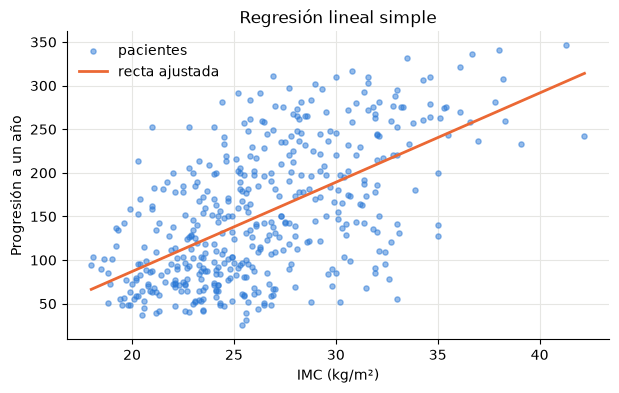

In [21]:
xs = np.linspace(progresion["bmi"].min(), progresion["bmi"].max(), 50)
fig, ax = plt.subplots()
ax.scatter(progresion["bmi"], progresion["target"], s=14, alpha=0.5, color=AZUL, label="pacientes")
ax.plot(xs, b0 + b1 * xs, color=NARANJA, linewidth=2, label="recta ajustada")
ax.set_xlabel("IMC (kg/m²)")
ax.set_ylabel("Progresión a un año")
ax.set_title("Regresión lineal simple")
ax.legend(frameon=False)
plt.show()

La recta capta la tendencia, pero los puntos están muy dispersos: el IMC solo explica una parte.

### Paso 6.2 · Regresión múltiple: las 10 variables
Separamos entrenamiento y prueba y medimos con dos métricas de regresión:
- **R²**: fracción de la variabilidad que el modelo explica (1 = perfecto, 0 = igual que predecir siempre el promedio).
- **MAE** (error absoluto medio): en promedio, ¿por cuántas unidades se equivoca?

In [22]:
from sklearn.metrics import mean_absolute_error, r2_score

Xp = progresion.drop(columns="target")
yp = progresion["target"]
Xp_train, Xp_test, yp_train, yp_test = train_test_split(Xp, yp, test_size=0.2, random_state=42)

lineal = LinearRegression().fit(Xp_train, yp_train)
pred = lineal.predict(Xp_test)
print(f"R² en prueba:  {r2_score(yp_test, pred):.2f}")
print(f"MAE en prueba: {mean_absolute_error(yp_test, pred):.1f} unidades")

R² en prueba:  0.45
MAE en prueba: 42.8 unidades


### Paso 6.3 · Leer los coeficientes

In [23]:
pd.Series(lineal.coef_, index=Xp.columns).sort_values(key=abs, ascending=False).round(2)

s5     67.11
sex   -23.06
s4     10.16
bmi     5.85
s1     -1.28
bp      1.20
s2      0.81
s3      0.60
s6      0.20
age     0.14
dtype: float64

**Tres lecciones en esta tabla:**
1. **El tamaño de un coeficiente depende de la unidad.** `s5` (logaritmo de los triglicéridos) tiene el coeficiente más grande porque su escala es pequeña: una unidad de logaritmo es un cambio enorme. Para comparar la importancia de las variables hay que estandarizarlas (lo haremos con la logística).
2. **Ajustar cambia los coeficientes.** Solo, el IMC valía unas 10 unidades por punto; junto a las demás variables vale cerca de 6. Parte de su efecto aparente lo explicaban otras variables relacionadas con él (presión, triglicéridos).
3. **La colinealidad.** `s1` (colesterol total) y `s2` (LDL) tienen signos **opuestos**, y un colesterol total "protector" no tiene sentido clínico. Ocurre porque el LDL es parte del colesterol total: están tan correlacionadas que el modelo reparte su efecto de forma inestable. Los coeficientes individuales dejan de ser interpretables, aunque las predicciones sigan siendo razonables.

Un R² cercano a 0.45 significa que más de la mitad de la variabilidad **no** se explica con estas variables. En clínica eso es normal: muchas cosas que influyen no están medidas.

## Bloque 7 · Regresión logística

### Qué es
A pesar de su nombre, **clasifica**. Calcula una suma ponderada (como la lineal) y la pasa por la función **sigmoide**, que la convierte en una probabilidad entre 0 y 1:

$$p = \frac{1}{1 + e^{-(b_0 + b_1 x_1 + \dots)}}$$

Cada coeficiente, al aplicarle la exponencial, se convierte en una **razón de momios** (*odds ratio*), el lenguaje habitual de la epidemiología.

| | |
|---|---|
| **Tipo de problema** | Clasificación (entrega probabilidades) |
| **Hiperparámetros** | `C`: inverso de la regularización (menor `C` = modelo más simple) |
| **Fortalezas** | Interpretable, probabilidades bien calibradas, rápida, liviana para desplegar |
| **Debilidades** | Frontera de decisión lineal; no capta interacciones si no se las damos |

**Ejemplos de uso en salud**
- Muchas escalas de riesgo clínico: por ejemplo, APACHE II estima la mortalidad en UCI con una ecuación logística.
- Probabilidad de readmisión, de complicación posquirúrgica o de un resultado positivo en un tamizaje.

### Paso 7.1 · La sigmoide en números

In [24]:
for z in [-4, -2, 0, 2, 4]:
    print(f"z = {z:+d}  ->  p = {1 / (1 + np.exp(-z)):.3f}")

z = -4  ->  p = 0.018
z = -2  ->  p = 0.119
z = +0  ->  p = 0.500
z = +2  ->  p = 0.881
z = +4  ->  p = 0.982


z = 0 da 0.5; valores grandes positivos se acercan a 1 y negativos a 0.

### Paso 7.2 · El pipeline: preparar y modelar en un solo objeto
La logística necesita dos preparaciones:
1. **Imputar** los faltantes (usaremos la **mediana** de cada columna).
2. **Estandarizar**: llevar cada variable a media 0 y desviación 1. Sin esto, la insulina (cientos) pesaría más que el pedigrí (menor que 1) solo por su escala.

**¿Por qué dentro de un `Pipeline`?** Porque la mediana y la desviación deben calcularse **solo con el entrenamiento**. Si las calculáramos con todos los datos, información de la prueba "se filtraría" al modelo (*data leakage*) y la evaluación saldría optimista. El pipeline lo garantiza: en `fit` aprende medianas y escalas del entrenamiento; en `predict` solo las aplica.

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

logistica = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(max_iter=1000))
logistica

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive est

Jupyter dibuja el pipeline: tres pasos en cadena. Ahora lo evaluamos:

In [26]:
evaluar("Regresión logística", logistica);

Regresión logística:  AUC 0.813 | sens 0.50 | espec 0.82 | VPP 0.60   (VP=27 FN=27 FP=18 VN=82)


Guarda estos números: **AUC ≈ 0.81** en prueba. Con umbral 0.5 la sensibilidad es solo 0.50: se pierde la mitad de los casos. Volveremos a esto en el Bloque 14.

### Paso 7.3 · Razones de momios
Como las variables están estandarizadas, cada razón de momios se lee **por cada desviación estándar** de aumento.

In [27]:
coef = logistica.named_steps["logisticregression"].coef_[0]
desviacion = logistica.named_steps["standardscaler"].scale_
pd.DataFrame({"razon_de_momios_por_DE": np.exp(coef), "una_DE_equivale_a": desviacion},
             index=VARIABLES).sort_values("razon_de_momios_por_DE", ascending=False).round(2)

,razon_de_momios_por_DE,una_DE_equivale_a
glucosa_2h,3.26,29.98
imc,1.99,6.82
embarazos,1.46,3.31
pedigri,1.26,0.33
edad,1.16,11.82
pliegue_triceps,1.03,8.88
presion_diastolica,0.96,12.27
insulina_2h,0.94,78.70


**Cómo leerlo:** por cada desviación estándar de glucosa a las 2 h (unos 30 mg/dL), los momios de diabetes se multiplican por más de 3. El IMC y los embarazos también aumentan el riesgo. Valores cercanos a 1 (presión, pliegue, insulina) indican poca contribución **una vez que las demás variables ya están en el modelo**.

Esta interpretabilidad es la razón por la que, más adelante, el servicio de IA podrá explicarle al médico **por qué** asignó un riesgo.

## Bloque 8 · Árboles de decisión


### Qué es
Una cadena de preguntas sí/no sobre las variables ("¿glucosa > 127?"). En cada paso elige la pregunta que mejor **separa** las clases (medido con el índice de Gini). Al final, cada hoja entrega la proporción de diabetes de los pacientes de entrenamiento que llegaron allí.

| | |
|---|---|
| **Tipo de problema** | Clasificación y regresión |
| **Hiperparámetros** | `max_depth` (profundidad máxima), `min_samples_leaf` (mínimo de pacientes por hoja) |
| **Fortalezas** | Se lee como un protocolo clínico; no necesita estandarizar; capta interacciones |
| **Debilidades** | Inestable (pequeños cambios en los datos cambian el árbol) y propenso al sobreajuste |

**Ejemplos de uso en salud**
- Protocolos de triage y algoritmos de guías de práctica clínica, que ya tienen forma de árbol.
- Algunas reglas clínicas de decisión se derivaron con este tipo de particiones recursivas de los datos.

Scikit-learn no acepta faltantes en todos sus árboles, así que conservamos el imputador (no necesita estandarizar).

### Paso 8.1 · Un árbol de profundidad 3

In [28]:
from sklearn.tree import DecisionTreeClassifier

arbol = make_pipeline(SimpleImputer(strategy="median"),
                      DecisionTreeClassifier(max_depth=3, random_state=42))
evaluar("Árbol de decisión", arbol);

Árbol de decisión:  AUC 0.764 | sens 0.26 | espec 0.92 | VPP 0.64   (VP=14 FN=40 FP=8 VN=92)


### Paso 8.2 · Leer las reglas
El árbol **es** un conjunto de reglas. `export_text` las imprime.

In [29]:
from sklearn.tree import export_text

print(export_text(arbol.named_steps["decisiontreeclassifier"], feature_names=VARIABLES, decimals=1))

|--- glucosa_2h <= 154.5
|   |--- imc <= 27.3
|   |   |--- glucosa_2h <= 151.5
|   |   |   |--- class: 0
|   |   |--- glucosa_2h >  151.5
|   |   |   |--- class: 1
|   |--- imc >  27.3
|   |   |--- edad <= 28.5
|   |   |   |--- class: 0
|   |   |--- edad >  28.5
|   |   |   |--- class: 0
|--- glucosa_2h >  154.5
|   |--- imc <= 23.1
|   |   |--- class: 0
|   |--- imc >  23.1
|   |   |--- insulina_2h <= 80.0
|   |   |   |--- class: 0
|   |   |--- insulina_2h >  80.0
|   |   |   |--- class: 1



`class: 0` significa sano y `class: 1`, diabetes. La primera pregunta es sobre la glucosa: el árbol encontró solo, a partir de los datos, la variable que un clínico miraría primero. Y como dibujo (aquí scikit-learn usa sus propios colores: **naranja = sano, azul = diabetes**; cuanto más intenso, más pura la hoja):

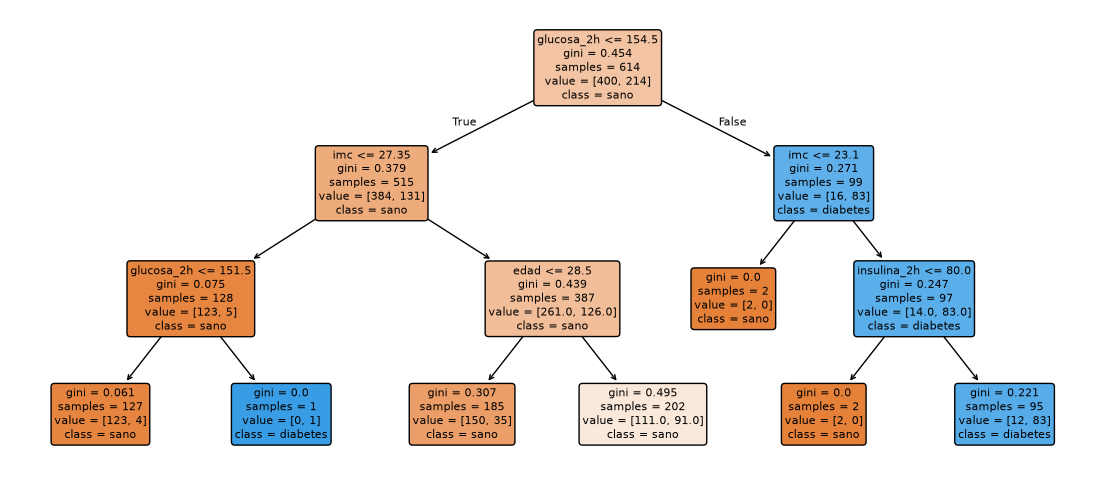

In [30]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arbol.named_steps["decisiontreeclassifier"], feature_names=VARIABLES,
          class_names=["sano", "diabetes"], filled=True, rounded=True, fontsize=8, ax=ax)
plt.show()

### Paso 8.3 · Sesgo y varianza, en vivo
Entrenamos árboles de profundidad 1 a 15 y comparamos dos números:
- **AUC en entrenamiento**: qué tan bien le va con los pacientes que vio.
- **AUC en validación cruzada (5 partes)**: dividimos el entrenamiento en 5 partes; entrenamos con 4 y medimos en la quinta, rotando. Es una estimación honesta sin tocar la prueba.

In [31]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
filas = []
for profundidad in [1, 2, 3, 4, 5, 6, 8, 10, 15]:
    m = make_pipeline(SimpleImputer(strategy="median"),
                      DecisionTreeClassifier(max_depth=profundidad, random_state=42)).fit(X_train, y_train)
    filas.append({"profundidad": profundidad,
                  "AUC_entrenamiento": roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
                  "AUC_validacion": cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc").mean()})
curva_arbol = pd.DataFrame(filas).set_index("profundidad")
curva_arbol

,AUC_entrenamiento,AUC_validacion
profundidad,,
1,0.674,0.682
2,0.761,0.738
3,0.826,0.757
4,0.864,0.788
5,0.889,0.769
6,0.921,0.743
8,0.972,0.682
10,0.994,0.663
15,1.000,0.650


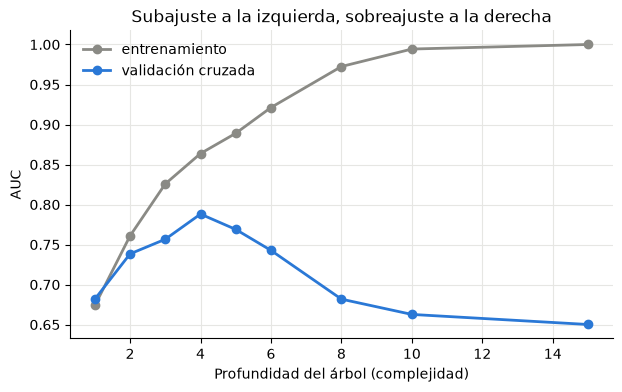

In [32]:
fig, ax = plt.subplots()
ax.plot(curva_arbol.index, curva_arbol["AUC_entrenamiento"], "o-", color=GRIS, linewidth=2, label="entrenamiento")
ax.plot(curva_arbol.index, curva_arbol["AUC_validacion"], "o-", color=AZUL, linewidth=2, label="validación cruzada")
ax.set_xlabel("Profundidad del árbol (complejidad)")
ax.set_ylabel("AUC")
ax.set_title("Subajuste a la izquierda, sobreajuste a la derecha")
ax.legend(frameon=False)
plt.show()

**Cómo leerlo:**
- **Profundidad 1-2**: ambas curvas bajas. El árbol es demasiado simple: **sesgo alto**.
- **Profundidad 4**: la validación llega a su máximo (≈ 0.79).
- **Profundidad 8 o más**: el entrenamiento llega casi a 1.0 (memoriza) mientras la validación **cae**: **varianza alta**.

La distancia entre las dos curvas es el tamaño del sobreajuste. Por eso nunca se elige un modelo por su desempeño en entrenamiento.

## Bloque 9 · K vecinos más cercanos (KNN)


### Qué es
No construye ninguna fórmula: **recuerda** a todos los pacientes de entrenamiento. Para uno nuevo, busca los `k` más parecidos (los más cercanos en distancia) y predice la proporción de diabetes entre ellos. Es razonamiento basado en casos: *"de las 15 pacientes más parecidas a esta, 9 desarrollaron diabetes"*.

| | |
|---|---|
| **Tipo de problema** | Clasificación y regresión |
| **Hiperparámetros** | `n_neighbors` (k), la métrica de distancia |
| **Fortalezas** | Intuitivo; explicable mostrando los casos parecidos; no supone ninguna forma |
| **Debilidades** | **Exige estandarizar**; lento con muchos datos; sufre con muchas variables |

**Ejemplos de uso en salud**
- Buscar "pacientes como este" para apoyar una decisión o para reclutar en un estudio.
- Recuperar estudios de imagen o casos clínicos similares. Es la misma idea de búsqueda por similitud que usa FAISS en los sistemas RAG.

**¿Por qué estandarizar?** Sin escalar, una diferencia de 100 µUI/mL en insulina pesaría mil veces más que una diferencia de 0.1 en el pedigrí, y la "cercanía" dependería casi solo de la insulina.

### Paso 9.1 · KNN con k = 15

In [33]:
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                    KNeighborsClassifier(n_neighbors=15))
evaluar("KNN", knn);

KNN:  AUC 0.807 | sens 0.56 | espec 0.84 | VPP 0.65   (VP=30 FN=24 FP=16 VN=84)


### Paso 9.2 · El efecto de k (sesgo y varianza otra vez)

In [34]:
filas = []
for k in [1, 3, 5, 15, 31, 51]:
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    filas.append({"k": k, "AUC_validacion": cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc").mean()})
pd.DataFrame(filas).set_index("k")

,AUC_validacion
k,
1,0.664
3,0.764
5,0.784
15,0.832
31,0.831
51,0.831


Con **k = 1** el modelo copia al vecino más cercano: memoriza (varianza alta) y su AUC es el peor. Con k entre 15 y 50 se estabiliza. Aquí el sesgo aparece a partir de valores de k mucho más grandes.

### Paso 9.3 · Ver a los vecinos
Lo más útil de KNN para un clínico: mostrar **quiénes** son las pacientes parecidas. Tomamos la primera paciente de prueba y buscamos sus 5 vecinas en el entrenamiento.

In [35]:
imputador, escalador, modelo_knn = knn.named_steps.values()
paciente = X_test.iloc[[0]]
distancias, indices = modelo_knn.kneighbors(escalador.transform(imputador.transform(paciente)), n_neighbors=5)

vecinas = X_train.iloc[indices[0]].assign(diabetes=y_train.iloc[indices[0]].values,
                                         distancia=distancias[0].round(2))
print("Paciente consultada:")
display(paciente)
print("Sus 5 vecinas más parecidas del entrenamiento:")
vecinas

Paciente consultada:


,embarazos,glucosa_2h,presion_diastolica,pliegue_triceps,insulina_2h,imc,pedigri,edad
44,7,159.0,64.0,NaN,NaN,27.4,0.294,40


Sus 5 vecinas más parecidas del entrenamiento:


,embarazos,glucosa_2h,presion_diastolica,pliegue_triceps,insulina_2h,imc,pedigri,edad,diabetes,distancia
192,7,159.0,66.0,NaN,NaN,30.4,0.383,36,1,0.64
749,6,162.0,62.0,NaN,NaN,24.3,0.178,50,1,1.08
404,5,168.0,64.0,NaN,NaN,32.9,0.135,41,1,1.16
107,4,144.0,58.0,28.0,140.0,29.5,0.287,37,0,1.23
568,4,154.0,72.0,29.0,126.0,31.3,0.338,37,0,1.30


Las vecinas tienen glucosa, IMC y edad parecidos. Esta misma operación, **buscar vecinos de la misma clase**, será el corazón del aumento de datos en la Parte B.

## Bloque 10 · Máquinas de vectores de soporte (SVM)


### Qué es
Busca la frontera que separa las clases **con el margen más ancho posible**. Solo los pacientes que quedan cerca de la frontera (los **vectores de soporte**) la definen; los demás no importan.

Cuando las clases no se separan con una línea recta, el **truco del kernel** permite fronteras curvas: el kernel `rbf` (función de base radial) mide similitud entre pacientes, de forma parecida a KNN pero suavizada.

| | |
|---|---|
| **Tipo de problema** | Clasificación (también regresión: SVR) |
| **Hiperparámetros** | `C` (cuánto castiga errores: alto = margen estrecho, riesgo de sobreajuste), `kernel`, `gamma` |
| **Fortalezas** | Muy eficaz con muchas variables y pocos pacientes |
| **Debilidades** | Exige estandarizar; lento con muchos datos; poco interpretable con kernel `rbf`; las probabilidades requieren un ajuste adicional (`probability=True`) |

**Ejemplos de uso en salud**
- Clasificación de señales biomédicas (ECG, EEG) a partir de características extraídas.
- Datos genómicos o de expresión génica: miles de variables y pocas muestras.

In [36]:
from sklearn.svm import SVC

svm_lineal = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                           SVC(kernel="linear", probability=True, random_state=42))
evaluar("SVM lineal", svm_lineal);

SVM lineal:  AUC 0.813 | sens 0.48 | espec 0.82 | VPP 0.59   (VP=26 FN=28 FP=18 VN=82)


In [37]:
svm_rbf = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        SVC(kernel="rbf", C=1.0, probability=True, random_state=42))
evaluar("SVM rbf", svm_rbf);

SVM rbf:  AUC 0.796 | sens 0.56 | espec 0.84 | VPP 0.65   (VP=30 FN=24 FP=16 VN=84)


¿Cuántos pacientes definen la frontera?

In [38]:
n_soporte = svm_rbf.named_steps["svc"].n_support_
print(f"Vectores de soporte: {n_soporte.sum()} de {len(X_train)} pacientes (sanos {n_soporte[0]}, diabetes {n_soporte[1]})")

Vectores de soporte: 350 de 614 pacientes (sanos 180, diabetes 170)


Más de la mitad de las pacientes están cerca de la frontera: las clases se **superponen** mucho en PIMA. Ningún modelo podrá separarlas perfectamente, porque las variables medidas no contienen toda la información.

## Bloque 11 · Ensambles de *boosting*


### La idea de los ensambles
Un árbol solo es inestable. Muchos árboles combinados son robustos. Hay dos estrategias:
- ***Bagging*** (por ejemplo, *Random Forest*): muchos árboles **en paralelo**, cada uno con una muestra distinta de los datos; se promedian.
- ***Boosting***: árboles pequeños **en secuencia**. Cada árbol nuevo se entrena para **corregir los errores** que dejaron los anteriores. *Gradient* boosting usa el gradiente de la función de error para saber en qué dirección corregir.

Hiperparámetros comunes a todos los *boosting*:
| Hiperparámetro | Qué controla |
|---|---|
| `n_estimators` | Cuántos árboles en la secuencia |
| `learning_rate` | Cuánto corrige cada árbol (pequeño = más lento pero más estable) |
| `max_depth` | Complejidad de cada árbol (suelen ser poco profundos: 3 a 6) |

### Las cuatro implementaciones
| Modelo | Qué lo distingue | Faltantes (`NaN`) |
|---|---|---|
| **Gradient Boosting** (scikit-learn) | La implementación clásica de referencia; simple | Necesita imputador |
| **XGBoost** | Regularización incorporada, muy optimizado; dominó competencias de datos tabulares | Los maneja solo |
| **LightGBM** | Crece los árboles hoja por hoja y agrupa valores en histogramas: muy rápido con millones de filas | Los maneja solo |
| **CatBoost** | Maneja variables categóricas directamente y usa *ordered boosting* para reducir el sobreajuste | Los maneja solo |

**Ejemplos de uso en salud**
- Alertas tempranas de deterioro o sepsis a partir de signos vitales y laboratorios.
- Predicción de readmisión o de no asistencia a citas con datos de la historia clínica electrónica.
- En general, son el estándar para datos **tabulares** (filas y columnas), como los de una historia clínica.

### Paso 11.1 · Gradient Boosting de scikit-learn

In [39]:
from sklearn.ensemble import GradientBoostingClassifier

gb = make_pipeline(SimpleImputer(strategy="median"),
                   GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42))
evaluar("Gradient Boosting", gb);

Gradient Boosting:  AUC 0.831 | sens 0.56 | espec 0.86 | VPP 0.68   (VP=30 FN=24 FP=14 VN=86)


### Paso 11.2 · XGBoost
Sin imputador: XGBoost aprende en cada división hacia qué lado enviar a los pacientes con el dato faltante.

In [40]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
evaluar("XGBoost", xgb);

XGBoost:  AUC 0.826 | sens 0.63 | espec 0.85 | VPP 0.69   (VP=34 FN=20 FP=15 VN=85)


### Paso 11.3 · LightGBM
`num_leaves` limita las hojas de cada árbol (su forma de controlar la complejidad). `verbose=-1` silencia sus mensajes.

In [41]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, random_state=42, verbose=-1)
evaluar("LightGBM", lgbm);

LightGBM:  AUC 0.819 | sens 0.61 | espec 0.84 | VPP 0.67   (VP=33 FN=21 FP=16 VN=84)


### Paso 11.4 · CatBoost
Si `catboost` no se instaló, la celda lo avisa y el cuaderno continúa.

In [42]:
try:
    from catboost import CatBoostClassifier
    cat = CatBoostClassifier(iterations=300, depth=4, learning_rate=0.05, verbose=0, random_seed=42)
    evaluar("CatBoost", cat)
except ImportError:
    print("CatBoost no está instalado: se omite.")

CatBoost:  AUC 0.817 | sens 0.59 | espec 0.82 | VPP 0.64   (VP=32 FN=22 FP=18 VN=82)


### Paso 11.5 · ¿Qué variables usó más XGBoost?
La **importancia** mide cuánto ayudó cada variable a mejorar las divisiones. A diferencia de los coeficientes de la logística, **no dice en qué dirección** (si sube o baja el riesgo).

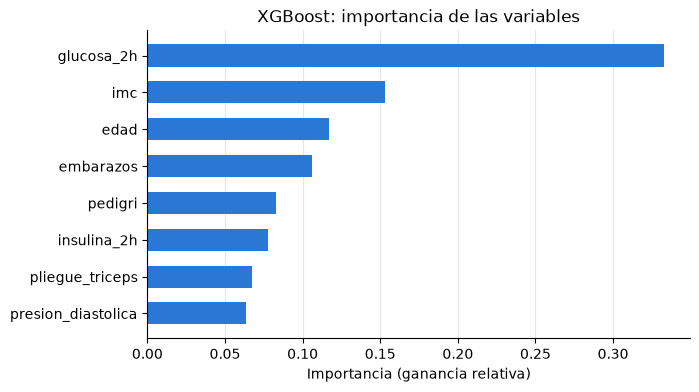

In [43]:
importancia = pd.Series(xgb.feature_importances_, index=VARIABLES).sort_values()
fig, ax = plt.subplots()
ax.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
ax.set_xlabel("Importancia (ganancia relativa)")
ax.set_title("XGBoost: importancia de las variables")
ax.grid(axis="y", visible=False)
plt.show()

La glucosa vuelve a dominar, igual que en la logística y en el árbol. Cuando modelos muy distintos coinciden, la señal es confiable.

## Bloque 12 · Perceptrón multicapa (MLP)


### Qué es
Una red neuronal. Cada **neurona** hace una suma ponderada de sus entradas y le aplica una **activación** no lineal (por defecto, ReLU: deja pasar los positivos y convierte los negativos en 0). Las neuronas se organizan en **capas ocultas**; la capa de salida entrega la probabilidad. Aprende ajustando todos los pesos con **retropropagación** (*backpropagation*) y descenso por gradiente.

| | |
|---|---|
| **Tipo de problema** | Clasificación y regresión |
| **Hiperparámetros** | `hidden_layer_sizes` (neuronas por capa), `alpha` (regularización L2), `learning_rate_init`, `max_iter` |
| **Fortalezas** | Aprende relaciones muy complejas; es la base del aprendizaje profundo (redes convolucionales para imágenes, modelos de lenguaje) |
| **Debilidades** | Necesita muchos datos; exige estandarizar; sensible a hiperparámetros; poco interpretable |

**Ejemplos de uso en salud**
- Sus versiones profundas: clasificación de retinografías (como el dataset APTOS), radiografías, ECG, texto clínico.
- En tablas pequeñas como PIMA rara vez supera a la logística o al *boosting*. Veamos por qué.

### Paso 12.1 · Una red grande y sin regularizar
Dos capas (16 y 8 neuronas) y regularización casi nula. Tiene cerca de 300 pesos para aprender con solo 614 pacientes.

In [44]:
from sklearn.neural_network import MLPClassifier

mlp_libre = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=(16, 8), alpha=1e-4, max_iter=3000, random_state=42))
evaluar("MLP sin regularizar", mlp_libre);

MLP sin regularizar:  AUC 0.819 | sens 0.63 | espec 0.77 | VPP 0.60   (VP=34 FN=20 FP=23 VN=77)


### Paso 12.2 · Una red regularizada
Una capa de 16 neuronas y `alpha=1.0`: penalizamos los pesos grandes para que la red no memorice.

In [45]:
mlp = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                    MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, max_iter=3000, random_state=42))
evaluar("MLP regularizado", mlp);

MLP regularizado:  AUC 0.816 | sens 0.56 | espec 0.80 | VPP 0.60   (VP=30 FN=24 FP=20 VN=80)


En esta única división de prueba las dos redes parecen iguales. Pero 154 pacientes son pocos: el azar de **cuáles** quedaron en la prueba pesa mucho. Comparémoslas con validación cruzada (5 divisiones distintas del entrenamiento), que es más confiable:

In [46]:
for nombre in ["MLP sin regularizar", "MLP regularizado"]:
    auc = cross_val_score(MODELOS[nombre], X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{nombre:20s}  AUC en validación cruzada {auc.mean():.3f} ± {auc.std():.3f}")

MLP sin regularizar   AUC en validación cruzada 0.780 ± 0.051
MLP regularizado      AUC en validación cruzada 0.846 ± 0.013


Ahora sí se ve la diferencia: sin regularizar, la red rinde peor y es más **inestable** (mayor desviación entre divisiones). Es otra cara del sesgo y la varianza: más parámetros que datos invitan a memorizar, y la regularización lo frena.

Las redes brillan cuando hay **muchos** datos (miles de imágenes); con 614 filas, un modelo simple compite de igual a igual. Y la lección sobre la prueba única nos lleva directo al siguiente bloque.

## Bloque 13 · Comparación justa con validación cruzada


### Qué vamos a entender
Hasta ahora cada modelo se midió con **una sola** división de prueba de 154 pacientes. Con tan pocos pacientes, el azar de la división mueve el AUC varias centésimas. Para **elegir** un modelo usamos validación cruzada de 5 partes **sobre el entrenamiento**, que da un promedio y una desviación estándar. La prueba sigue intacta.

Recorremos el diccionario `MODELOS` que `evaluar` fue llenando. El MLP sin regularizar se omite (ya vimos por qué).

In [47]:
filas = []
for nombre, modelo in MODELOS.items():
    if nombre == "MLP sin regularizar":
        continue
    auc = cross_val_score(modelo, X_train, y_train, cv=cv, scoring="roc_auc")
    filas.append({"modelo": nombre, "AUC_cv": auc.mean(), "desviacion": auc.std(),
                  "AUC_prueba": RESULTADOS[nombre]["AUC"]})
comparacion = pd.DataFrame(filas).set_index("modelo").sort_values("AUC_cv", ascending=False)
comparacion

,AUC_cv,desviacion,AUC_prueba
modelo,,,
MLP regularizado,0.846,0.013,0.816
SVM lineal,0.845,0.016,0.813
Regresión logística,0.843,0.019,0.813
SVM rbf,0.833,0.023,0.796
KNN,0.832,0.030,0.807
Gradient Boosting,0.819,0.016,0.831
CatBoost,0.817,0.024,0.817
XGBoost,0.812,0.024,0.826
LightGBM,0.790,0.025,0.819


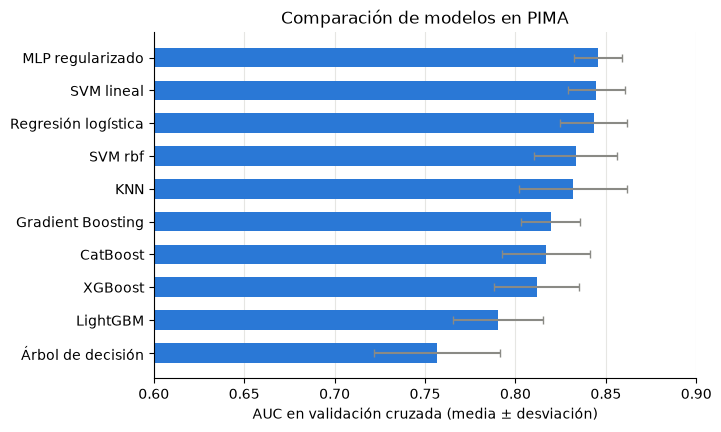

In [48]:
orden = comparacion.sort_values("AUC_cv")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(orden.index, orden["AUC_cv"], xerr=orden["desviacion"], color=AZUL, height=0.6,
        error_kw={"ecolor": GRIS, "capsize": 3})
ax.set_xlim(0.6, 0.9)
ax.set_xlabel("AUC en validación cruzada (media ± desviación)")
ax.set_title("Comparación de modelos en PIMA")
ax.grid(axis="y", visible=False)
plt.show()

### Dos observaciones antes de elegir
- **Los tres primeros empatan.** MLP regularizado, SVM lineal y regresión logística se separan por milésimas, mucho menos que su desviación (≈ 0.015).
- **La prueba única engaña.** Mira la columna `AUC_prueba`: por ella habríamos elegido Gradient Boosting o XGBoost, que en validación cruzada quedan por debajo. Si eligiéramos mirando la prueba, estaríamos ajustando la decisión a 154 pacientes concretos. Por eso **se elige con validación cruzada** y la prueba solo confirma.

### Qué modelo usará el servicio
Entre modelos empatados, decidimos por otros criterios:

| Criterio | Regresión logística |
|---|---|
| Desempeño | Entre los mejores (AUC ≈ 0.84 en validación) |
| **Explicabilidad** | Puede decir, paciente por paciente, qué variables subieron o bajaron su riesgo |
| Despliegue | Liviana: corre en CPU en microsegundos y no necesita librerías extra en Docker |
| Probabilidades | Bien calibradas: un 30 % significa aproximadamente 30 % |

> **El mejor modelo no es el más complejo, sino el más simple que resuelve bien el problema y que el equipo clínico puede entender.**

## Bloque 14 · El umbral: de una probabilidad a una decisión


### Qué vamos a entender
El modelo entrega una **probabilidad**. Convertirla en "positivo" o "negativo" exige un **umbral**, y 0.5 no tiene nada de especial. En **tamizaje** preferimos no perder casos (alta sensibilidad), aunque eso signifique más pruebas confirmatorias. Miremos el efecto con la logística:

In [49]:
prob_log = logistica.predict_proba(X_test)[:, 1]
filas = []
for umbral in [0.2, 0.3, 0.4, 0.5, 0.6]:
    vn, fp, fn, vp = confusion_matrix(y_test, prob_log >= umbral).ravel()
    filas.append({"umbral": umbral, "sensibilidad": vp / (vp + fn), "especificidad": vn / (vn + fp),
                  "VPP": vp / (vp + fp), "marcadas_positivas": vp + fp, "casos_perdidos": fn})
pd.DataFrame(filas).set_index("umbral")

,sensibilidad,especificidad,VPP,marcadas_positivas,casos_perdidos
umbral,,,,,
0.2,0.889,0.61,0.552,87,6
0.3,0.796,0.71,0.597,72,11
0.4,0.648,0.78,0.614,57,19
0.5,0.500,0.82,0.600,45,27
0.6,0.463,0.86,0.641,39,29


Bajar el umbral de 0.5 a **0.30** sube la sensibilidad de cerca de 0.50 a **0.80**: de 54 pacientes con diabetes en la prueba, pasamos de perder 27 a perder 11. El precio es marcar más pacientes para confirmación.

El servicio usará:
| Probabilidad | Nivel | Acción sugerida |
|---|---|---|
| menor de 0.30 | **bajo** | Tamizaje negativo, controles habituales |
| 0.30 a 0.60 | **moderado** | Tamizaje positivo: considerar prueba confirmatoria |
| 0.60 o más | **alto** | Tamizaje positivo: considerar prueba confirmatoria |

> Estos cortes son decisiones **clínicas y de política de salud**, no del algoritmo. En un sistema real los define el equipo clínico según la guía vigente y la capacidad de atención.

## Bloque 15 · Sesgo en acción: ¿funciona igual para todas?


Respondemos la pregunta del Bloque 5 con la logística, en dos grupos de edad de la prueba.

In [50]:
filas = []
for grupo, mascara in [("21-29 años", X_test["edad"] < 30), ("30 años o más", X_test["edad"] >= 30)]:
    yt, pt = y_test[mascara], prob_log[mascara]
    filas.append({"grupo": grupo, "pacientes": int(mascara.sum()), "prevalencia": yt.mean(),
                  "AUC": roc_auc_score(yt, pt),
                  "sensibilidad_umbral_0.5": recall_score(yt, pt >= 0.5),
                  "sensibilidad_umbral_0.3": recall_score(yt, pt >= 0.3)})
pd.DataFrame(filas).set_index("grupo")

,pacientes,prevalencia,AUC,sensibilidad_umbral_0.5,sensibilidad_umbral_0.3
grupo,,,,,
21-29 años,85,0.188,0.770,0.312,0.562
30 años o más,69,0.551,0.761,0.579,0.895


**Cómo leerlo:**
- El **AUC es parecido** en ambos grupos: el modelo ordena igual de bien.
- Pero con umbral 0.5, la **sensibilidad en las jóvenes es mucho menor**: el modelo pierde a la mayoría de las jóvenes con diabetes. Como en ellas la diabetes es menos frecuente y la edad joven "baja" el riesgo, sus probabilidades rara vez pasan de 0.5.
- Bajar el umbral a 0.30 mejora a ambos grupos (las jóvenes pasan de cerca de 0.31 a 0.56), pero **la brecha persiste**: con el mismo umbral, una joven con diabetes tiene muchas más probabilidades de pasar desapercibida que una mayor. Corregirlo exigiría, por ejemplo, umbrales por grupo o más datos de pacientes jóvenes, y esa es una decisión clínica y ética, no técnica.

Un AUC global de 0.81 escondía que el modelo falla más en un grupo concreto. Y hay sesgos que **ni siquiera podemos medir aquí**: no hay hombres, ni otras etnias, ni pacientes colombianas. Por eso el servicio de la Parte C **se negará** a analizar pacientes fuera de la población de entrenamiento.

### Para pensar
1. Si este modelo se usara en Cali sin validación local, ¿qué grupos podrían quedar mal atendidos?
2. ¿Qué datos necesitarías para validarlo en población colombiana?

<details><summary>Ver una respuesta posible</summary>

1. Hombres, menores de 21 años y, en general, pacientes cuya relación entre glucosa, IMC y riesgo difiera de la de las mujeres pimas (por genética, dieta, acceso a salud). También las jóvenes, como vimos.
2. Una cohorte local con las mismas variables medidas de la misma forma y con el desenlace conocido tras el seguimiento, que permita recalcular AUC, sensibilidad y calibración por subgrupos (sexo, edad, región), con aval ético y cumpliendo la Ley 1581 de 2012.
</details>

# Parte B · Aumento de datos: 200 pacientes a partir de pacientes reales

## Bloque 16 · Por qué y cómo aumentar datos


### Qué vamos a entender
Queremos poblar el sistema con **200 pacientes** cuyos datos se agrupen de forma realista alrededor de la diabetes: unas sanas, otras en riesgo, otras con la enfermedad. Hay tres caminos:

| Camino | Problema |
|---|---|
| Inventar números al azar (como la semilla de la semana 8) | No conserva las relaciones reales entre variables (glucosa alta junto a IMC alto, por ejemplo) |
| Copiar pacientes reales | Duplica personas: problema de privacidad y datos repetidos |
| **Aumentar** a partir de pacientes reales | Cada paciente nuevo se crea **entre** dos pacientes reales parecidos |

### La técnica: interpolación entre vecinos (la idea de SMOTE)
Para crear un paciente:
1. Tomamos un paciente real **base**.
2. Buscamos sus `k = 5` vecinos más cercanos **de la misma clase** (KNN, Bloque 9) y elegimos uno al azar.
3. Sorteamos un número `u` entre 0 y 1.
4. El paciente nuevo es: **nuevo = base + u × (vecino − base)**.

Con `u = 0` sería una copia de la base; con `u = 1`, del vecino; con `u = 0.4`, queda a 40 % del camino entre ambos. Como los dos son de la misma clase y parecidos, el nuevo cae **dentro del mismo grupo** (*cluster*) de la patología. La etiqueta del nuevo es la de sus dos "padres".

### Dos decisiones importantes
- **¿De qué pacientes partimos?** Del **20 % de prueba**. El modelo nunca los vio, así que evaluarlo después con los sintéticos no será hacer trampa. Si partiéramos del entrenamiento, los sintéticos serían "casi" pacientes que el modelo ya conoce y el resultado saldría inflado (fuga de datos).
- **¿Y los faltantes?** Se conservan: si a la base le falta la insulina, al nuevo también. En la vida real no a todas las pacientes se les mide todo, y el servicio debe saber manejarlo.

### Paso 16.1 · La fuente
Convertimos a arreglos de NumPy (así funcionará también dentro del servicio, que no usa pandas).

In [51]:
X_fuente = X_test.to_numpy()
y_fuente = y_test.to_numpy()
print(f"Pacientes fuente: {len(X_fuente)} | con diabetes: {y_fuente.sum()} ({y_fuente.mean():.1%})")

Pacientes fuente: 154 | con diabetes: 54 (35.1%)


### Paso 16.2 · Preparar la medida de distancia
Para **medir** quién es vecino de quién necesitamos datos completos y en la misma escala: imputamos y estandarizamos. Ojo: esta versión solo se usa para **medir distancias**; los valores que se interpolan son los **originales**.

In [52]:
X_distancia = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X_fuente))
print(X_distancia.shape, "| medias ≈ 0:", X_distancia.mean(axis=0).round(2))

(154, 8) | medias ≈ 0: [ 0. -0. -0.  0. -0.  0.  0.  0.]


### Paso 16.3 · Los vecinos, dentro de una clase
Buscamos vecinos **solo entre pacientes con diabetes**. Pedimos `k + 1 = 6` porque el paciente más cercano a cada uno es **él mismo** (distancia 0); lo quitamos con `[:, 1:]`.

In [53]:
from sklearn.neighbors import NearestNeighbors

K = 5
idx_diabetes = np.flatnonzero(y_fuente == 1)          # posiciones de las pacientes con diabetes
buscador = NearestNeighbors(n_neighbors=K + 1).fit(X_distancia[idx_diabetes])
vecinos_diabetes = buscador.kneighbors(X_distancia[idx_diabetes], return_distance=False)[:, 1:]
print("Vecinos de la primera paciente con diabetes (posiciones dentro del grupo):", vecinos_diabetes[0])

Vecinos de la primera paciente con diabetes (posiciones dentro del grupo): [33 15  7 10 13]


### Paso 16.4 · Crear UN paciente a mano
Antes de automatizar, hagámoslo una vez para ver cada pieza.

In [54]:
rng_demo = np.random.default_rng(0)
base = X_fuente[idx_diabetes[0]]
vecino = X_fuente[idx_diabetes[vecinos_diabetes[0, 0]]]
u = rng_demo.random()
nuevo = np.where(np.isnan(vecino), base, base + u * (vecino - base))

print(f"u = {u:.2f}")
pd.DataFrame({"base": base, "vecino": vecino, "nuevo": nuevo}, index=VARIABLES).round(2)

u = 0.64


,base,vecino,nuevo
embarazos,7.00,6.00,6.36
glucosa_2h,114.00,124.00,120.37
presion_diastolica,64.00,72.00,69.10
pliegue_triceps,NaN,NaN,NaN
insulina_2h,NaN,NaN,NaN
imc,27.40,27.60,27.53
pedigri,0.73,0.37,0.50
edad,34.00,29.00,30.82


Cada valor del paciente nuevo queda entre el de la base y el del vecino (más cerca de la base si `u` es pequeño). Si el vecino tiene un faltante, se usa el valor de la base; si la base tiene un faltante, el nuevo también (`base + ...` con `NaN` da `NaN`).

### Paso 16.5 · La función completa
`aumentar` repite el paso anterior para ambas clases:
- Calcula cuántos pacientes nuevos de cada clase crear para **conservar la prevalencia** de la fuente (35 % de 200 = 70 con diabetes).
- Para cada clase, busca vecinos solo dentro de esa clase.
- Guarda la etiqueta y la **fila de origen** (para trazabilidad).
- Al final **mezcla** el orden, para que las clases no queden en bloque.

`semilla=2026` hace que todos obtengan exactamente los mismos 200 pacientes. **Esta función es idéntica a la que usará el servicio.**

In [55]:
def aumentar(X, y, n=200, k=5, semilla=2026):
    """Devuelve (X_nuevo, y_nuevo, fila_origen). Mantiene la proporción de diabetes de la fuente."""
    rng = np.random.default_rng(semilla)
    Xd = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))

    n_diabetes = round(n * y.mean())
    filas, etiquetas, origen = [], [], []
    for clase, cuantos in [(1, n_diabetes), (0, n - n_diabetes)]:
        idx = np.flatnonzero(y == clase)
        vecinos = NearestNeighbors(n_neighbors=k + 1).fit(Xd[idx]).kneighbors(
            Xd[idx], return_distance=False)[:, 1:]
        for _ in range(cuantos):
            a = rng.integers(len(idx))                    # paciente base
            b = vecinos[a, rng.integers(k)]               # uno de sus k vecinos
            base, vecino = X[idx[a]], X[idx[b]]
            u = rng.random()
            nuevo = np.where(np.isnan(vecino), base, base + u * (vecino - base))
            filas.append(nuevo)
            etiquetas.append(clase)
            origen.append(int(idx[a]))
    orden = rng.permutation(n)
    return np.array(filas)[orden], np.array(etiquetas)[orden], np.array(origen)[orden]

### Paso 16.6 · Dejar los valores clínicamente presentables
La interpolación produce cosas como 3.47 embarazos o una edad de 38.62 años. `redondear` recorta cada variable a su **rango plausible** (los extremos observados en PIMA) y la deja con los decimales que se usan en clínica. `np.clip` y `np.round` respetan los `NaN`.

In [56]:
LIMITES = {  # variable: (mínimo, máximo, decimales)
    "embarazos": (0, 17, 0), "glucosa_2h": (44, 199, 0), "presion_diastolica": (24, 122, 0),
    "pliegue_triceps": (7, 99, 0), "insulina_2h": (14, 846, 0), "imc": (18.2, 67.1, 1),
    "pedigri": (0.078, 2.42, 3), "edad": (21, 81, 0),
}


def redondear(X):
    X = X.copy()
    for j, v in enumerate(VARIABLES):
        lo, hi, dec = LIMITES[v]
        X[:, j] = np.round(np.clip(X[:, j], lo, hi), dec)
    return X

### Paso 16.7 · Generar los 200

In [57]:
X_sint, y_sint, origen_sint = aumentar(X_fuente, y_fuente)
X_sint = redondear(X_sint)

sint = pd.DataFrame(X_sint, columns=VARIABLES).assign(diabetes=y_sint)
sint.index = [f"55{i + 1:08d}" for i in range(len(sint))]     # el documento que tendrán en el sistema
sint.index.name = "documento"
print(sint.shape, "| con diabetes:", int(y_sint.sum()))
sint.head()

(200, 9) | con diabetes: 70


,embarazos,glucosa_2h,presion_diastolica,pliegue_triceps,insulina_2h,imc,pedigri,edad,diabetes
documento,,,,,,,,,
5500000001,1.0,NaN,50.0,22.0,NaN,24.9,0.179,22.0,0
5500000002,6.0,86.0,67.0,NaN,NaN,25.6,0.308,43.0,0
5500000003,9.0,149.0,90.0,21.0,NaN,32.0,0.769,40.0,1
5500000004,2.0,112.0,73.0,NaN,NaN,44.9,0.789,25.0,0
5500000005,0.0,130.0,76.0,NaN,NaN,42.7,0.270,26.0,1


El índice ya muestra el **documento** que cada paciente tendrá en el sistema (`5500000001` a `5500000200`).

### Paso 16.8 · Controles de calidad
Un generador de datos se verifica, no se da por bueno. Tres controles:

In [58]:
print("1. Prevalencia real vs sintética:", f"{y_fuente.mean():.1%} vs {y_sint.mean():.1%}")
print("\n2. Rangos (min / max) de la cohorte sintética:")
display(sint[VARIABLES].agg(["min", "max"]).T)
print("3. Faltantes por variable:")
sint[VARIABLES].isna().sum()

1. Prevalencia real vs sintética: 35.1% vs 35.0%

2. Rangos (min / max) de la cohorte sintética:


,min,max
embarazos,0.000,14.00
glucosa_2h,67.000,193.00
presion_diastolica,50.000,94.00
pliegue_triceps,12.000,63.00
insulina_2h,14.000,678.00
imc,19.400,54.60
pedigri,0.107,2.14
edad,21.000,68.00


3. Faltantes por variable:


embarazos               0
glucosa_2h              2
presion_diastolica     19
pliegue_triceps        75
insulina_2h           118
imc                     3
pedigri                 0
edad                    0
dtype: int64

Ahora el control de **privacidad**: ningún paciente sintético debe ser una copia exacta de uno real. Medimos, para cada sintético, la distancia al paciente real más cercano (con la misma medida estandarizada). Si alguna fuera 0, habríamos copiado a alguien.

In [59]:
prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_fuente)
dist_real, _ = NearestNeighbors(n_neighbors=1).fit(prep.transform(X_fuente)).kneighbors(prep.transform(X_sint))
verificar("ningún sintético es copia exacta de un real", dist_real.min() > 0, f"(distancia mínima {dist_real.min():.3f})")
print(f"Distancia mediana al real más cercano: {np.median(dist_real):.2f}")
print("Sintéticos a menos de 0.05 de un real:", int((dist_real < 0.05).sum()))

OK     ningún sintético es copia exacta de un real (distancia mínima 0.003)
Distancia mediana al real más cercano: 0.48
Sintéticos a menos de 0.05 de un real: 13


Ninguna copia exacta, y la distancia típica es de media desviación estándar. Pero fíjate en la distancia **mínima**: es casi cero. Cuando el sorteo da `u` muy cercano a 0, el paciente nuevo queda prácticamente encima de su base. Con un dataset público como PIMA no es un problema; con datos reales de pacientes sí lo sería, y se descartarían los sintéticos demasiado cercanos (queda como ejercicio de extensión).

### Paso 16.9 · ¿Se conservan los grupos de la patología?
Glucosa contra IMC, reales a la izquierda y sintéticos a la derecha, con el mismo color por clase.

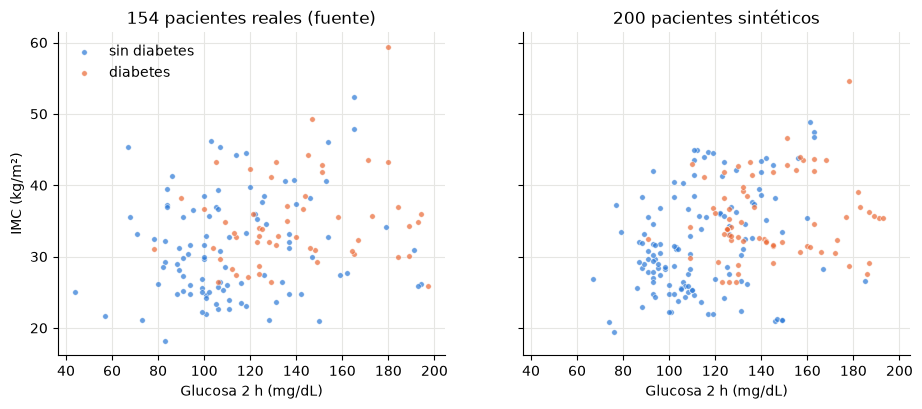

In [60]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
g, i = VARIABLES.index("glucosa_2h"), VARIABLES.index("imc")
for ax, (Xg, yg, titulo) in zip(ejes, [(X_fuente, y_fuente, "154 pacientes reales (fuente)"),
                                       (X_sint, y_sint, "200 pacientes sintéticos")]):
    for clase, color, nombre in [(0, AZUL, "sin diabetes"), (1, NARANJA, "diabetes")]:
        ax.scatter(Xg[yg == clase, g], Xg[yg == clase, i], s=16, alpha=0.7, color=color,
                   edgecolor="white", linewidth=0.5, label=nombre)
    ax.set_title(titulo)
    ax.set_xlabel("Glucosa 2 h (mg/dL)")
ejes[0].set_ylabel("IMC (kg/m²)")
ejes[0].legend(frameon=False)
plt.show()

Los sintéticos ocupan **las mismas regiones** que los reales: las pacientes con diabetes se concentran con glucosa alta e IMC alto, las sanas abajo a la izquierda, y ambas nubes se superponen en el centro, igual que en los datos reales. Los grupos (*clusters*) de la patología se conservaron sin copiar a nadie.

### Paso 16.10 · El modelo, con los 200 sintéticos

In [61]:
prob_sint = logistica.predict_proba(pd.DataFrame(X_sint, columns=VARIABLES))[:, 1]
print(f"AUC en los 200 sintéticos: {roc_auc_score(y_sint, prob_sint):.3f}")
print(f"AUC en los 154 reales de prueba: {RESULTADOS['Regresión logística']['AUC']:.3f}")

AUC en los 200 sintéticos: 0.861
AUC en los 154 reales de prueba: 0.813


Valores parecidos: los sintéticos se comportan como la población de la que nacieron. Suele salir un poco más alto porque la interpolación "suaviza" los casos extremos. **Un buen resultado con datos sintéticos no es una validación clínica**: solo confirma que el pipeline funciona.

Esto es exactamente lo que hará el servicio en la Parte C: los mismos 200 pacientes (mismo documento, mismos valores), pero guardados en la base de datos como historias clínicas.

# Parte C · El microservicio de IA

## Bloque 17 · Arquitectura del servicio


### Qué vamos a construir
```
                         navegador
                             |
                     front (nginx) :8080
                  /api/      |       /ml/
                    |                 |
            api (FastAPI) :8000    ml (FastAPI) :8001   <- NUEVO
             |        |               |
        orthanc     db (PostgreSQL) --+
        (PACS)      pacientes, encuentros, observaciones, ml_cohort, ml_reports
```

### Decisiones de diseño (debes poder explicarlas)
| Decisión | Por qué |
|---|---|
| **Un servicio aparte**, no más rutas en la API | Sus dependencias (scikit-learn, NumPy) son pesadas y cambian a otro ritmo; si falla, la historia clínica sigue funcionando (igual que con el PACS en la semana 8); se puede escalar o reemplazar sin tocar la API |
| **Misma base de datos** | El reporte debe quedar **en la historia clínica**, que vive en PostgreSQL |
| **Mismo `JWT_SECRET` que la API** | El servicio no tiene `/login`: valida los tokens que firma la API. Un solo inicio de sesión para todo el sistema |
| **La misma regla de acceso** | Un médico solo puede analizar a **sus** pacientes (`404` si no es suyo). Crear la cohorte y analizarla completa es solo para el admin |
| **El modelo se entrena dentro del contenedor** | Con el `pima.csv` y la misma división del cuaderno. Así no dependemos de un archivo de modelo compilado con otra versión de scikit-learn |
| **El reporte es un encuentro** de tipo `Reporte IA` | Aparece en la ficha que ya existe, sin cambiar el frontend |
| **Todo queda auditado** | Cada análisis se guarda en `ml_reports` (versión del modelo, probabilidad, factores) y en `audit_log` |

### Las rutas del servicio
| Método y ruta | Quién | Qué hace |
|---|---|---|
| `GET /health` | Cualquiera | Estado del servicio |
| `GET /modelo` | Con sesión | Versión y métricas del modelo en servicio |
| `POST /entrenar` | Admin | Vuelve a entrenar |
| `POST /cohorte` | Admin | Crea los 200 pacientes sintéticos |
| `POST /analizar/{id}` | Médico (sus pacientes) o admin | Analiza un paciente y adjunta el reporte |
| `POST /analizar-cohorte` | Admin | Analiza los 200 |
| `GET /evaluacion` | Admin | Compara predicciones con la etiqueta verdadera |
| `GET /reportes/{id}` | Médico (sus pacientes) o admin | Historial de reportes |
| `GET /fhir/RiskAssessment?patient=` | Médico (sus pacientes) o admin | Los reportes como recursos HL7 FHIR |

Construiremos `main.py` **en cuatro etapas**, probando al final de cada una.

## Bloque 18 · Reorientar la base de datos


### Qué vamos a entender
La base de la semana 8 guarda pacientes, encuentros y signos vitales. Para la IA necesitamos tres cosas nuevas, **sin borrar nada**:

| Cambio | Para qué |
|---|---|
| Columna `patients.cohort` | Marcar a los 200 pacientes de la cohorte (`pima-sint-2026`). Los 50 de la semana 8 quedan con `NULL` |
| Tabla `ml_cohort` | Dos datos de la cohorte que **no son observaciones clínicas**: el índice de pedigrí (no tiene código LOINC; si lo metiéramos en `observations`, la ruta FHIR lo publicaría con un código falso) y la **etiqueta verdadera**, que solo sirve para evaluar |
| Tabla `ml_reports` | Cada análisis: versión del modelo, probabilidad, nivel, factores (en `JSONB`) y variables faltantes |

Los valores clínicos de PIMA (glucosa, presión, IMC...) **sí** van a `observations`, con su código LOINC y su unidad UCUM, igual que los signos vitales de la semana 8. Así la ficha y la ruta FHIR los muestran sin cambiar una línea de la API.

Como la de la semana 8, la migración es **idempotente** (`IF NOT EXISTS`).

In [62]:
%%writefile db/migracion_semana9.sql
-- Migración de la semana 9: la base de datos se prepara para el servicio de IA.
-- Idempotente, igual que la de la semana 8: se puede ejecutar varias veces.
-- No borra nada: los 50 pacientes de la semana 8 y sus imágenes siguen intactos.

-- 1. Cada paciente puede pertenecer a una cohorte (NULL = paciente "normal" del sistema)
ALTER TABLE patients ADD COLUMN IF NOT EXISTS cohort VARCHAR(40);
CREATE INDEX IF NOT EXISTS idx_patients_cohort ON patients (cohort);

-- 2. Datos de la cohorte que NO son observaciones clínicas
--    diabetes_pedigree: resume los antecedentes familiares de diabetes. No tiene código LOINC,
--                       así que no va en observations (la ruta FHIR lo publicaría con un código falso).
--    outcome:           la etiqueta verdadera (1 = desarrolló diabetes). SOLO sirve para evaluar
--                       el modelo: el servicio nunca la lee para predecir.
CREATE TABLE IF NOT EXISTS ml_cohort (
    patient_id        INTEGER PRIMARY KEY REFERENCES patients(id) ON DELETE CASCADE,
    diabetes_pedigree NUMERIC(5,3),
    outcome           SMALLINT NOT NULL CHECK (outcome IN (0, 1)),
    source_row        INTEGER NOT NULL,
    created_at        TIMESTAMPTZ NOT NULL DEFAULT now()
);

-- 3. Cada análisis del modelo queda guardado: qué versión, qué probabilidad y por qué
CREATE TABLE IF NOT EXISTS ml_reports (
    id            SERIAL PRIMARY KEY,
    patient_id    INTEGER NOT NULL REFERENCES patients(id) ON DELETE CASCADE,
    encounter_id  INTEGER REFERENCES encounters(id) ON DELETE SET NULL,
    model_version VARCHAR(40) NOT NULL,
    probability   NUMERIC(5,4) NOT NULL CHECK (probability BETWEEN 0 AND 1),
    risk_level    VARCHAR(10) NOT NULL CHECK (risk_level IN ('bajo', 'moderado', 'alto')),
    factors       JSONB NOT NULL,
    missing       TEXT[] NOT NULL DEFAULT '{}',
    created_by    VARCHAR(50) NOT NULL,
    created_at    TIMESTAMPTZ NOT NULL DEFAULT now()
);
CREATE INDEX IF NOT EXISTS idx_ml_reports_patient ON ml_reports (patient_id);

Writing db/migracion_semana9.sql


In [63]:
migrar("db/migracion_semana9.sql")

ALTER TABLE
CREATE INDEX
CREATE TABLE
CREATE TABLE
CREATE INDEX
 
Migración OK


Ejecútala **otra vez**: deben aparecer avisos `already exists, skipping` y ningún error. Eso demuestra que es idempotente.

In [64]:
migrar("db/migracion_semana9.sql")

ALTER TABLE
CREATE INDEX
CREATE TABLE
CREATE TABLE
CREATE INDEX
 NOTICE:  column "cohort" of relation "patients" already exists, skipping
NOTICE:  relation "idx_patients_cohort" already exists, skipping
NOTICE:  relation "ml_cohort" already exists, skipping
NOTICE:  relation "ml_reports" already exists, skipping
NOTICE:  relation "idx_ml_reports_patient" already exists, skipping

Migración OK


In [65]:
psql("\\d ml_reports")
psql("SELECT count(*) AS pacientes, count(cohort) AS en_cohorte FROM patients")

                                        Table "public.ml_reports"
    Column     |           Type           | Collation | Nullable |                Default                 
---------------+--------------------------+-----------+----------+----------------------------------------
 id            | integer                  |           | not null | nextval('ml_reports_id_seq'::regclass)
 patient_id    | integer                  |           | not null | 
 encounter_id  | integer                  |           |          | 
 model_version | character varying(40)    |           | not null | 
 probability   | numeric(5,4)             |           | not null | 
 risk_level    | character varying(10)    |           | not null | 
 factors       | jsonb                    |           | not null | 
 missing       | text[]                   |           | not null | '{}'::text[]
 created_by    | character varying(50)    |           | not null | 
 created_at    | timestamp with time zone |           | no

Debes ver las columnas de `ml_reports` y **50 pacientes, 0 en cohorte** (o 51 si conservas el paciente de la semana 7). Todavía no hemos creado la cohorte.

## Bloque 19 · El servicio, archivo por archivo (etapa 1: el modelo)


La carpeta `ml/` quedará así:
```
ml/
  Dockerfile
  requirements.txt
  data/pima.csv      <- ya lo descargaste en el Bloque 2
  db.py              <- conexión, regla de acceso y auditoría
  seguridad.py       <- validación del token de la API
  datos.py           <- el dataset y su traducción a LOINC
  modelo.py          <- entrenar, predecir y explicar
  cohorte.py         <- los 200 pacientes (Bloque 20)
  lectura.py         <- de la historia clínica al vector de variables (Bloque 21)
  reporte.py         <- redactar y guardar el reporte (Bloque 21)
  main.py            <- las rutas, en cuatro etapas
```

### Paso 19.1 · Dependencias
Solo lo necesario. **No** instalamos XGBoost ni pandas: el modelo elegido (logística) solo necesita scikit-learn y NumPy, y una imagen más pequeña se construye y se despliega más rápido. Las versiones van fijadas para que todos construyan la misma imagen.

In [66]:
%%writefile ml/requirements.txt
fastapi==0.115.0
uvicorn[standard]==0.30.6
psycopg2-binary==2.9.9
PyJWT==2.9.0
numpy==2.1.3
scikit-learn==1.5.2

Writing ml/requirements.txt


### Paso 19.2 · Dockerfile
Igual al de la API, con el puerto **8001**.

In [67]:
%%writefile ml/Dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY . .
CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8001"]

Writing ml/Dockerfile


### Paso 19.3 · `db.py`: la base de datos
Es la **misma** base de la API, pero el servicio tiene su propio módulo: un microservicio no importa código de otro, solo comparte **contratos** (las tablas y el secreto del token). Contiene tres funciones que ya conoces de la semana 8:
- `db()`: una consulta con parámetros seguros (nunca texto concatenado).
- `paciente_visible()`: la regla de acceso por rol, con `404` en lugar de `403`.
- `auditar()`: escribe en el mismo `audit_log`.

In [68]:
%%writefile ml/db.py
"""Acceso a la base de datos del servicio de IA.

Es la MISMA base de la API (mismo contenedor db), pero el servicio tiene su propio
módulo: un microservicio no importa código de otro, solo comparte contratos
(las tablas, el secreto del token).
"""
import os

import psycopg2
import psycopg2.extras
from fastapi import HTTPException

DB_CONFIG = dict(
    host=os.getenv("DB_HOST", "db"),
    port=int(os.getenv("DB_PORT", 5432)),
    dbname=os.getenv("DB_NAME", "salud_digital"),
    user=os.getenv("DB_USER", "salud_admin"),
    password=os.getenv("DB_PASSWORD", "salud_dev_2026"),
)


def get_conn():
    return psycopg2.connect(**DB_CONFIG)


def db(sql, params=(), *, one=False, write=False):
    """Igual que en la API: una consulta, parámetros seguros, conexión cerrada al final."""
    conn = get_conn()
    try:
        with conn.cursor(cursor_factory=psycopg2.extras.RealDictCursor) as cur:
            cur.execute(sql, params)
            result = None
            if cur.description:
                result = cur.fetchone() if one else cur.fetchall()
            if write:
                conn.commit()
            return result
    except Exception:
        conn.rollback()
        raise
    finally:
        conn.close()


def paciente_visible(patient_id, user):
    """La misma regla de acceso de la API: el admin ve todos, el médico solo los suyos.
    404 (no 403) para no revelar que el paciente existe."""
    sql = "SELECT * FROM patients WHERE id = %s"
    params = [patient_id]
    if user["role"] != "admin":
        sql += " AND medico_id = %s"
        params.append(user["id"])
    fila = db(sql, params, one=True)
    if not fila:
        raise HTTPException(status_code=404, detail="Paciente no encontrado")
    return fila


def auditar(user, accion, patient_id=None, detalle=None):
    """Misma tabla audit_log de la semana 8: quién hizo qué, sin datos clínicos."""
    db("INSERT INTO audit_log (username, action, patient_id, detail) VALUES (%s, %s, %s, %s)",
       (user["username"], accion, patient_id, detalle), write=True)

Writing ml/db.py


### Paso 19.4 · `seguridad.py`: confiar en los tokens de la API
El servicio **no** tiene `/login`. Cuando llega una petición con `Authorization: Bearer <token>`, verifica la firma con `JWT_SECRET`. Si la firma es válida, el token lo emitió la API y podemos creer lo que dice (usuario y rol). Si el secreto no coincidiera con el de la API, **todas** las peticiones responderían `401`.

In [69]:
%%writefile ml/seguridad.py
"""Validación del token JWT emitido por la API.

El servicio de IA NO tiene /login: confía en los tokens que firma la API porque
comparte con ella el secreto JWT_SECRET (variable de entorno en docker-compose.yml).
"""
import os

import jwt
from fastapi import Depends, HTTPException
from fastapi.security import HTTPAuthorizationCredentials, HTTPBearer

JWT_SECRET = os.getenv("JWT_SECRET", "cambia-este-secreto-en-produccion")
bearer = HTTPBearer(auto_error=False)


def usuario_actual(creds: HTTPAuthorizationCredentials | None = Depends(bearer)) -> dict:
    if creds is None:
        raise HTTPException(status_code=401, detail="Falta iniciar sesión")
    try:
        datos = jwt.decode(creds.credentials, JWT_SECRET, algorithms=["HS256"])
    except jwt.ExpiredSignatureError:
        raise HTTPException(status_code=401, detail="La sesión expiró, ingresa de nuevo")
    except jwt.InvalidTokenError:
        raise HTTPException(status_code=401, detail="Sesión inválida")
    return {"id": datos["uid"], "username": datos["sub"], "role": datos["role"]}


def solo_admin(user: dict = Depends(usuario_actual)) -> dict:
    if user["role"] != "admin":
        raise HTTPException(status_code=403, detail="Solo el administrador puede hacer esto")
    return user

Writing ml/seguridad.py


### Paso 19.5 · `datos.py`: el dataset y su traducción a la historia clínica
Tres cosas que ya hiciste en el cuaderno, ahora en el servicio:
- `cargar()`: lee el CSV y convierte los ceros imposibles en `NaN` (Bloque 2).
- `dividir()`: la **misma** división 80/20 con `random_state=42` (Bloque 3).
- `LIMITES`: los rangos plausibles (Bloque 16).

Y una nueva: el diccionario `LOINC`, que traduce cada variable a un código LOINC, un nombre para la ficha y una unidad UCUM. Es el puente entre el mundo del modelo (columnas) y el de la historia clínica (observaciones codificadas).

In [70]:
%%writefile ml/datos.py
"""El dataset REAL (PIMA) y cómo se traduce a la historia clínica.

Todo el servicio parte de aquí: el modelo se entrena con estas columnas y la cohorte
sintética se genera a partir de ellas.
"""
from pathlib import Path

import numpy as np
from sklearn.model_selection import train_test_split

RUTA = Path(__file__).parent / "data" / "pima.csv"

# Orden de las columnas del archivo original (la última es la etiqueta)
VARIABLES = ["embarazos", "glucosa_2h", "presion_diastolica", "pliegue_triceps",
             "insulina_2h", "imc", "pedigri", "edad"]

# En PIMA un 0 en estas columnas no es un valor real: significa "no se midió"
CERO_ES_FALTANTE = ["glucosa_2h", "presion_diastolica", "pliegue_triceps", "insulina_2h", "imc"]

# Variable -> (código LOINC, nombre en la ficha, unidad UCUM)
# pedigri no tiene LOINC (va en la tabla ml_cohort) y edad sale de la fecha de nacimiento
LOINC = {
    "embarazos":          ("11996-6", "Número de embarazos", "{#}"),
    "glucosa_2h":         ("1518-0",  "Glucosa 2 h poscarga (75 g)", "mg/dL"),
    "presion_diastolica": ("8462-4",  "Presión arterial diastólica", "mm[Hg]"),
    "pliegue_triceps":    ("8354-3",  "Pliegue cutáneo tricipital", "mm"),
    "insulina_2h":        ("27860-6", "Insulina 2 h poscarga (75 g)", "u[IU]/mL"),
    "imc":                ("39156-5", "Índice de masa corporal", "kg/m2"),
}

# Rango plausible de cada variable (los extremos observados en PIMA) y sus decimales
LIMITES = {
    "embarazos": (0, 17, 0), "glucosa_2h": (44, 199, 0), "presion_diastolica": (24, 122, 0),
    "pliegue_triceps": (7, 99, 0), "insulina_2h": (14, 846, 0), "imc": (18.2, 67.1, 1),
    "pedigri": (0.078, 2.42, 3), "edad": (21, 81, 0),
}

SEMILLA = 42


def cargar():
    """Lee el CSV y convierte los ceros imposibles en NaN (faltantes)."""
    datos = np.loadtxt(RUTA, delimiter=",")
    X, y = datos[:, :8].copy(), datos[:, 8].astype(int)
    for nombre in CERO_ES_FALTANTE:
        j = VARIABLES.index(nombre)
        X[X[:, j] == 0, j] = np.nan
    return X, y


def dividir():
    """La MISMA división que en el cuaderno: 80 % para entrenar, 20 % que el modelo nunca ve.
    De ese 20 % nacerán los 200 pacientes sintéticos."""
    X, y = cargar()
    return train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

Writing ml/datos.py


### Paso 19.6 · `modelo.py`: entrenar, predecir y explicar
- `construir()`: el mismo pipeline del Bloque 7.
- `entrenar()`: validación cruzada, entrenamiento y métricas en la prueba. Guarda el modelo **en memoria**.
- `obtener()`: entrena la primera vez que se necesita; después reutiliza el modelo.
- `nivel()`: los cortes del Bloque 14.
- `explicar()`: el aporte de cada variable al riesgo de **este** paciente = coeficiente × valor estandarizado. Un aporte positivo empuja el riesgo hacia arriba respecto a una paciente promedio; uno negativo, hacia abajo. Es lo que permite escribir en el reporte *por qué* salió ese riesgo.

`VERSION` identifica el modelo. Cada reporte la guarda: si mañana cambiamos el modelo, sabremos con cuál se hizo cada análisis.

In [71]:
%%writefile ml/modelo.py
"""Entrenamiento, predicción y explicación del modelo de riesgo de diabetes."""
import datetime as dt

import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from datos import SEMILLA, VARIABLES, dividir

VERSION = "logreg-pima-1.0"
UMBRAL_TAMIZAJE = 0.30          # elegido en el cuaderno: sensibilidad cercana a 0.8

_estado = {"modelo": None, "metricas": None}


def construir():
    """El mismo pipeline del cuaderno: imputar -> estandarizar -> regresión logística."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(max_iter=1000))


def entrenar():
    Xtr, Xte, ytr, yte = dividir()
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    auc_cv = cross_val_score(construir(), Xtr, ytr, cv=cv, scoring="roc_auc")

    modelo = construir().fit(Xtr, ytr)
    prob = modelo.predict_proba(Xte)[:, 1]
    positivo = prob >= UMBRAL_TAMIZAJE
    metricas = {
        "version": VERSION,
        "entrenado": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "n_entrenamiento": int(len(ytr)),
        "n_prueba": int(len(yte)),
        "auc_validacion_cruzada": round(float(auc_cv.mean()), 3),
        "auc_prueba": round(float(roc_auc_score(yte, prob)), 3),
        "umbral_tamizaje": UMBRAL_TAMIZAJE,
        "sensibilidad_prueba": round(float(positivo[yte == 1].mean()), 3),
        "especificidad_prueba": round(float((~positivo)[yte == 0].mean()), 3),
    }
    _estado.update(modelo=modelo, metricas=metricas)
    return metricas


def obtener():
    """Entrena la primera vez que se necesita; después reutiliza el modelo en memoria."""
    if _estado["modelo"] is None:
        entrenar()
    return _estado["modelo"]


def metricas():
    obtener()
    return _estado["metricas"]


def nivel(prob):
    if prob < UMBRAL_TAMIZAJE:
        return "bajo"
    return "moderado" if prob < 0.60 else "alto"


def predecir(x):
    """x: vector con las 8 variables en el orden de VARIABLES (NaN = faltante)."""
    return float(obtener().predict_proba(np.asarray(x, dtype=float).reshape(1, -1))[0, 1])


def explicar(x):
    """Contribución de cada variable al riesgo = coeficiente x valor estandarizado.
    Positiva: empuja el riesgo hacia arriba frente a un paciente promedio. Negativa: hacia abajo."""
    modelo = obtener()
    imputador, escalador, logistica = modelo.named_steps.values()
    x = np.asarray(x, dtype=float).reshape(1, -1)
    z = escalador.transform(imputador.transform(x))[0]
    aportes = logistica.coef_[0] * z
    filas = [{"variable": v, "valor": None if np.isnan(x[0, j]) else float(x[0, j]),
              "aporte": round(float(aportes[j]), 3)} for j, v in enumerate(VARIABLES)]
    return sorted(filas, key=lambda f: abs(f["aporte"]), reverse=True)

Writing ml/modelo.py


### Paso 19.7 · `main.py`, etapa 1
Tres rutas: `/health` (sin sesión, para saber si el servicio vive), `/modelo` (con sesión) y `/entrenar` (solo admin).

In [72]:
%%writefile ml/main.py
"""Servicio de IA de Salud Digital — etapa 1: el modelo."""
from fastapi import Depends, FastAPI

import modelo
from db import auditar, db
from seguridad import solo_admin, usuario_actual

app = FastAPI(title="Salud Digital · Servicio de IA", version="9.0")


@app.get("/health", tags=["Sistema"])
def health():
    estado = {"status": "ok", "servicio": "ml"}
    try:
        db("SELECT 1")
        estado["db"] = "ok"
    except Exception:
        estado["db"] = "error"
    estado["modelo"] = modelo.VERSION
    return estado


@app.get("/modelo", tags=["Modelo"])
def ver_modelo(user: dict = Depends(usuario_actual)):
    """Qué modelo está en servicio y qué tan bien le fue en datos que no vio."""
    return modelo.metricas()


@app.post("/entrenar", tags=["Modelo"])
def reentrenar(admin: dict = Depends(solo_admin)):
    metr = modelo.entrenar()
    auditar(admin, "ml_train", detalle=f"{metr['version']} auc={metr['auc_prueba']}")
    return metr

Writing ml/main.py


### Paso 19.8 · Agregar el servicio a `docker-compose.yml`
El servicio `ml` es nuevo. Fíjate en tres detalles:
- `JWT_SECRET` es **idéntico** al de la API (si no, `401` en todo).
- Publica el puerto `8001` solo para que este cuaderno lo pruebe directamente. Al publicar la aplicación, solo se expone el `8080` (nginx).
- `front` ahora depende también de `ml`: en el Bloque 23 nginx reenviará `/ml/` y necesita que `ml` exista al arrancar.

In [73]:
%%writefile docker-compose.yml
# Sin container_name: así carpetas distintas (c7, c8...) no chocan por el nombre de un contenedor.
services:
  db:
    image: postgres:16
    restart: unless-stopped
    environment:
      POSTGRES_USER: salud_admin
      POSTGRES_PASSWORD: salud_dev_2026
      POSTGRES_DB: salud_digital
    ports:
      - "5432:5432"
    volumes:
      - pgdata:/var/lib/postgresql/data
      - ./init-scripts:/docker-entrypoint-initdb.d
    healthcheck:
      test: ["CMD-SHELL", "pg_isready -U salud_admin -d salud_digital"]
      interval: 5s
      timeout: 5s
      retries: 5

  api:
    build: ./api
    restart: unless-stopped
    environment:
      DB_HOST: db
      DB_PORT: 5432
      DB_NAME: salud_digital
      DB_USER: salud_admin
      DB_PASSWORD: salud_dev_2026
      JWT_SECRET: salud_digital_jwt_dev_2026   # en producción: valor largo y secreto, fuera del repositorio
      JWT_MINUTES: 60
      ORTHANC_URL: http://orthanc:8042
      ORTHANC_USER: api
      ORTHANC_PASSWORD: orthanc_dev_2026
    ports:
      - "8000:8000"
    depends_on:
      db:
        condition: service_healthy
      orthanc:
        condition: service_started

  # NUEVO (semana 9): el servicio de IA. Misma base de datos y MISMO JWT_SECRET que la API:
  # así acepta los tokens que la API firma sin tener un /login propio.
  ml:
    build: ./ml
    restart: unless-stopped
    environment:
      DB_HOST: db
      DB_PORT: 5432
      DB_NAME: salud_digital
      DB_USER: salud_admin
      DB_PASSWORD: salud_dev_2026
      JWT_SECRET: salud_digital_jwt_dev_2026   # debe ser idéntico al de la API
    ports:
      - "8001:8001"                            # solo para el laboratorio (el cuaderno lo usa directo)
    depends_on:
      db:
        condition: service_healthy

  orthanc:
    image: orthancteam/orthanc:25.5.1
    restart: unless-stopped
    environment:
      ORTHANC__NAME: "Salud Digital PACS"
      ORTHANC__AUTHENTICATION_ENABLED: "true"
      ORTHANC__REMOTE_ACCESS_ALLOWED: "true"
      ORTHANC__REGISTERED_USERS: |
        {"api": "orthanc_dev_2026"}
    ports:
      - "127.0.0.1:8042:8042"        # solo para el laboratorio, y solo desde tu propio equipo
    volumes:
      - orthanc-data:/var/lib/orthanc/db

  front:
    image: nginx:1.27-alpine
    restart: unless-stopped
    ports:
      - "8080:80"
    volumes:
      - ./front:/usr/share/nginx/html:ro
      - ./nginx/default.conf:/etc/nginx/conf.d/default.conf:ro
    depends_on:
      - api
      - ml                            # nginx necesita que "ml" exista al arrancar

volumes:
  pgdata:
  orthanc-data:

Overwriting docker-compose.yml


### Paso 19.9 · Construir y encender
La primera construcción descarga scikit-learn dentro de la imagen: puede tardar **2 a 4 minutos**. Las siguientes serán rápidas porque Docker reutiliza la capa de dependencias mientras `requirements.txt` no cambie.

In [74]:
!docker compose up -d --build ml

#1 [internal] load local bake definitions
#1 reading from stdin 523B 0.0s done
#1 DONE 0.0s

#2 [internal] load build definition from Dockerfile
#2 transferring dockerfile: 231B 0.0s done
#2 DONE 0.1s

#3 [internal] load metadata for docker.io/library/python:3.11-slim
#3 DONE 1.4s

#4 [internal] load .dockerignore
#4 transferring context: 2B done
#4 DONE 0.1s

#5 [internal] load build context
#5 transferring context: 33.87kB 0.0s done
#5 DONE 0.1s

#6 [1/5] FROM docker.io/library/python:3.11-slim@sha256:e41613d42d4891e4930f79523f93f81bbc7632584ec65e36ab055f41a800b41e
#6 resolve docker.io/library/python:3.11-slim@sha256:e41613d42d4891e4930f79523f93f81bbc7632584ec65e36ab055f41a800b41e 0.1s done
#6 DONE 0.1s

#7 [2/5] WORKDIR /app
#7 CACHED

#8 [3/5] COPY requirements.txt .
#8 DONE 0.0s

#9 [4/5] RUN pip install --no-cache-dir -r requirements.txt
#9 3.382 Collecting fastapi==0.115.0 (from -r requirements.txt (line 1))
#9 3.441   Downloading fastapi-0.115.0-py3-none-any.whl.metadata (27 kB

 Image c9-ml Building 
 Image c9-ml Built 
 Container c9-db-1 Running 
 Container c9-ml-1 Creating 
 Container c9-ml-1 Created 
 Container c9-db-1 Waiting 
 Container c9-db-1 Healthy 
 Container c9-ml-1 Starting 
 Container c9-ml-1 Started 


In [75]:
!docker compose ps ml

NAME      IMAGE     COMMAND                  SERVICE   CREATED         STATUS                  PORTS
c9-ml-1   c9-ml     "uvicorn main:app --…"   ml        2 seconds ago   Up Less than a second   0.0.0.0:8001->8001/tcp, [::]:8001->8001/tcp


### Qué debes ver

In [76]:
import time
time.sleep(3)                        # damos unos segundos a que uvicorn arranque

estado, datos = ml("GET", "/health")
verificar("el servicio responde /health", estado == 200 and datos["db"] == "ok", datos)

estado, _ = ml("GET", "/modelo")
verificar("/modelo sin token: 401", estado == 401)

admin = entrar("ana_admin", "clave123")
luis = entrar("luis_medico", "clave456")
maria = entrar("maria_medica", "clave789")

estado, metricas = ml("GET", "/modelo", token=luis)
verificar("/modelo con el token de la API: 200", estado == 200)
metricas

OK     el servicio responde /health {'status': 'ok', 'servicio': 'ml', 'db': 'ok', 'modelo': 'logreg-pima-1.0'}
OK     /modelo sin token: 401 
OK     /modelo con el token de la API: 200 


{'version': 'logreg-pima-1.0',
 'entrenado': '2026-09-28T16:58:12+00:00',
 'n_entrenamiento': 614,
 'n_prueba': 154,
 'auc_validacion_cruzada': 0.843,
 'auc_prueba': 0.813,
 'umbral_tamizaje': 0.3,
 'sensibilidad_prueba': 0.796,
 'especificidad_prueba': 0.71}

El servicio aceptó un token que **no emitió él**, sino la API: comparten el secreto. Y como `/modelo` es la primera ruta que necesita el modelo, en ese momento se entrenó.

Ahora la prueba más importante: **¿el servicio obtuvo lo mismo que tú en el cuaderno?** Si la división, la limpieza o el pipeline difirieran en algo, estos números no coincidirían.

In [77]:
auc_cuaderno = RESULTADOS["Regresión logística"]["AUC"]
verificar("mismo AUC de prueba que el cuaderno", abs(metricas["auc_prueba"] - auc_cuaderno) < 0.002,
          f"(servicio {metricas['auc_prueba']} | cuaderno {auc_cuaderno:.3f})")
verificar("mismo tamaño de entrenamiento", metricas["n_entrenamiento"] == len(X_train))

estado, _ = ml("POST", "/entrenar", token=luis)
verificar("un médico no puede reentrenar: 403", estado == 403)

OK     mismo AUC de prueba que el cuaderno (servicio 0.813 | cuaderno 0.813)
OK     mismo tamaño de entrenamiento 
OK     un médico no puede reentrenar: 403 


True

### Si algo falla
- **`ConnectionRefusedError` o `RemoteDisconnected`**: el contenedor todavía arranca o se cayó. Mira `!docker compose logs ml --tail 30`.
- **`FileNotFoundError: .../data/pima.csv`** en los logs: no ejecutaste el Paso 2.1, o la carpeta `ml/data/` no existía al construir. Ejecútalo y reconstruye.
- **Todo responde `401`**: el `JWT_SECRET` de `ml` no es igual al de `api` en `docker-compose.yml`.
- **`db: error`**: el servicio `db` no está encendido (`!docker compose up -d db`).

## Bloque 20 · La cohorte en la base de datos (etapa 2)


### Qué vamos a entender
`cohorte.py` tiene dos partes:
- **Generar** (`aumentar`, `redondear`, `generar`): exactamente las funciones de la Parte B. `generar()` parte del mismo 20 % de prueba.
- **Guardar** (`guardar`): convierte cada fila en una historia clínica, **en una sola transacción** (o entran los 200 o no entra ninguno):

| Dato de la fila | Dónde queda |
|---|---|
| Nombre, apellidos, ciudad, EPS | `patients` (sexo `F`: PIMA solo tiene mujeres) |
| Edad | `patients.birth_date`, calculada hacia atrás desde una fecha fija |
| Médico responsable | Se alternan `luis_medico` y `maria_medica` (100 cada uno) |
| Glucosa, presión, pliegue, insulina, IMC, embarazos | Un encuentro `Control` ("Tamizaje metabólico") con sus `observations` LOINC. **Si el valor falta, no se inventa**: simplemente no se crea esa observación |
| Pedigrí y etiqueta verdadera | `ml_cohort` |

Si la cohorte ya existe, `guardar` no hace nada: es **idempotente**.

In [78]:
%%writefile ml/cohorte.py
"""Cohorte sintética de 200 pacientes creada por AUMENTO DE DATOS a partir de pacientes reales.

Técnica: interpolación entre vecinos de la misma clase (la idea de SMOTE).
  nuevo = base + u * (vecino - base),   con u al azar entre 0 y 1
El paciente nuevo queda "entre" dos pacientes reales parecidos: conserva los grupos
(clusters) de la patología sin copiar a ninguna persona.
"""
import datetime as dt
import random

import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from datos import LIMITES, LOINC, VARIABLES, dividir

COHORTE = "pima-sint-2026"
N_PACIENTES = 200
K_VECINOS = 5
SEMILLA_COHORTE = 2026
HOY = dt.date(2026, 9, 28)                        # fecha fija: mismos datos para todos
COLOMBIA = dt.timezone(dt.timedelta(hours=-5))

NOMBRES = ["María", "Luisa", "Camila", "Valentina", "Paola", "Diana", "Carolina", "Natalia",
           "Andrea", "Laura", "Sandra", "Marcela", "Juliana", "Daniela", "Yolanda", "Gloria",
           "Martha", "Liliana", "Katherine", "Isabella", "Ángela", "Beatriz", "Claudia", "Rosa"]
APELLIDOS = ["Gómez", "Rodríguez", "Martínez", "López", "García", "Hernández", "Ramírez",
             "Torres", "Vargas", "Castro", "Ortiz", "Rojas", "Moreno", "Muñoz", "Cárdenas",
             "Valencia", "Escobar", "Cortés", "Quintero", "Arias", "Salazar", "Restrepo",
             "Zapata", "Bedoya", "Mosquera", "Caicedo", "Angulo", "Lasso"]
CIUDADES = ["Cali"] * 16 + ["Jamundí", "Palmira", "Yumbo"]
EPS = ["Sanitas", "Sura", "Nueva EPS", "Coosalud", "Emssanar", "Salud Total", "Famisanar"]


def aumentar(X, y, n=N_PACIENTES, k=K_VECINOS, semilla=SEMILLA_COHORTE):
    """Devuelve (X_nuevo, y_nuevo, fila_origen). Mantiene la proporción de diabetes de la fuente."""
    rng = np.random.default_rng(semilla)
    # Para MEDIR distancias rellenamos faltantes y estandarizamos (si no, la insulina dominaría).
    # Los valores que se interpolan son los originales, no los rellenados.
    Xd = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))

    n_diabetes = round(n * y.mean())
    filas, etiquetas, origen = [], [], []
    for clase, cuantos in [(1, n_diabetes), (0, n - n_diabetes)]:
        idx = np.flatnonzero(y == clase)                          # solo pacientes de esta clase
        vecinos = NearestNeighbors(n_neighbors=k + 1).fit(Xd[idx]).kneighbors(
            Xd[idx], return_distance=False)[:, 1:]                # [:, 1:] quita al propio paciente
        for _ in range(cuantos):
            a = rng.integers(len(idx))                            # paciente base
            b = vecinos[a, rng.integers(k)]                       # uno de sus k vecinos
            base, vecino = X[idx[a]], X[idx[b]]
            u = rng.random()
            # Si al vecino le falta un dato, se usa el de la base. Si a la base le falta, sigue faltando.
            nuevo = np.where(np.isnan(vecino), base, base + u * (vecino - base))
            filas.append(nuevo)
            etiquetas.append(clase)
            origen.append(int(idx[a]))
    orden = rng.permutation(n)                                    # mezclamos las dos clases
    return np.array(filas)[orden], np.array(etiquetas)[orden], np.array(origen)[orden]


def redondear(X):
    """Recorta cada variable a su rango plausible y la deja con los decimales clínicos."""
    X = X.copy()
    for j, v in enumerate(VARIABLES):
        lo, hi, dec = LIMITES[v]
        X[:, j] = np.round(np.clip(X[:, j], lo, hi), dec)         # clip y round respetan los NaN
    return X


def generar():
    """Los 200 pacientes, a partir del 20 % de PIMA que el modelo nunca vio."""
    _, X_fuente, _, y_fuente = dividir()
    Xn, yn, origen = aumentar(X_fuente, y_fuente)
    return redondear(Xn), yn, origen


def guardar(conn):
    """Inserta la cohorte en la base de datos en UNA transacción. Si ya existe, no hace nada."""
    cur = conn.cursor()
    cur.execute("SELECT count(*) FROM patients WHERE cohort = %s", (COHORTE,))
    ya = cur.fetchone()[0]
    if ya:
        return {"creados": 0, "ya_existian": ya}

    cur.execute("SELECT id FROM users WHERE username IN ('luis_medico', 'maria_medica') ORDER BY username")
    medicos = [r[0] for r in cur.fetchall()]
    if len(medicos) < 2:
        raise RuntimeError("Faltan los médicos de práctica (create_users.py de la semana 8)")

    X, y, origen = generar()
    edad_j = VARIABLES.index("edad")
    ped_j = VARIABLES.index("pedigri")
    creados = 0
    for i, fila in enumerate(X):
        rng = random.Random(f"cohorte-{i}")
        documento = f"55{i + 1:08d}"                             # 5500000001 ... 5500000200
        edad = int(fila[edad_j])
        nacimiento = HOY.replace(year=HOY.year - edad) - dt.timedelta(days=rng.randint(0, 364))
        cur.execute(
            """INSERT INTO patients (document_id, first_name, last_name, birth_date, sex,
                   medico_id, city, eps, cohort)
               VALUES (%s, %s, %s, %s, 'F', %s, %s, %s, %s)
               ON CONFLICT (document_id) DO NOTHING RETURNING id""",
            (documento, rng.choice(NOMBRES), " ".join(rng.sample(APELLIDOS, 2)), nacimiento,
             medicos[i % 2], rng.choice(CIUDADES), rng.choice(EPS), COHORTE),
        )
        row = cur.fetchone()
        if row is None:
            continue
        patient_id = row[0]
        creados += 1

        momento = dt.datetime.combine(HOY - dt.timedelta(days=rng.randint(1, 60)),
                                      dt.time(rng.randint(7, 11), rng.choice([0, 15, 30, 45])),
                                      tzinfo=COLOMBIA)
        cur.execute(
            """INSERT INTO encounters (patient_id, encounter_date, encounter_type, notes, created_by)
               VALUES (%s, %s, 'Control', %s, 'servicio_ml') RETURNING id""",
            (patient_id, momento, "Tamizaje metabólico: curva de tolerancia oral a la glucosa (75 g)."),
        )
        encounter_id = cur.fetchone()[0]
        for variable, (codigo, nombre, unidad) in LOINC.items():
            valor = fila[VARIABLES.index(variable)]
            if np.isnan(valor):                                   # dato faltante: no se inventa
                continue
            cur.execute(
                """INSERT INTO observations (encounter_id, loinc_code, loinc_display,
                       value_numeric, value_unit, observed_at) VALUES (%s, %s, %s, %s, %s, %s)""",
                (encounter_id, codigo, nombre, float(valor), unidad, momento),
            )
        cur.execute(
            "INSERT INTO ml_cohort (patient_id, diabetes_pedigree, outcome, source_row) VALUES (%s, %s, %s, %s)",
            (patient_id, float(fila[ped_j]), int(y[i]), int(origen[i])),
        )
    conn.commit()
    return {"creados": creados, "ya_existian": 0, "con_diabetes": int(y.sum())}

Writing ml/cohorte.py


### Paso 20.1 · `main.py`, etapa 2
Se agrega `POST /cohorte`, solo para el admin.

In [79]:
%%writefile ml/main.py
"""Servicio de IA de Salud Digital — etapa 2: la cohorte."""
from fastapi import Depends, FastAPI

import cohorte
import modelo
from db import auditar, db, get_conn
from seguridad import solo_admin, usuario_actual

app = FastAPI(title="Salud Digital · Servicio de IA", version="9.0")


@app.get("/health", tags=["Sistema"])
def health():
    estado = {"status": "ok", "servicio": "ml"}
    try:
        db("SELECT 1")
        estado["db"] = "ok"
    except Exception:
        estado["db"] = "error"
    estado["modelo"] = modelo.VERSION
    return estado


@app.get("/modelo", tags=["Modelo"])
def ver_modelo(user: dict = Depends(usuario_actual)):
    """Qué modelo está en servicio y qué tan bien le fue en datos que no vio."""
    return modelo.metricas()


@app.post("/entrenar", tags=["Modelo"])
def reentrenar(admin: dict = Depends(solo_admin)):
    metr = modelo.entrenar()
    auditar(admin, "ml_train", detalle=f"{metr['version']} auc={metr['auc_prueba']}")
    return metr


@app.post("/cohorte", status_code=201, tags=["Cohorte"])
def crear_cohorte(admin: dict = Depends(solo_admin)):
    """Crea los 200 pacientes sintéticos. Si ya existen, no duplica nada."""
    conn = get_conn()
    try:
        resultado = cohorte.guardar(conn)
    except Exception:
        conn.rollback()
        raise
    finally:
        conn.close()
    auditar(admin, "ml_cohort", detalle=f"creados={resultado['creados']}")
    return {"cohorte": cohorte.COHORTE, **resultado}

Overwriting ml/main.py


In [80]:
!docker compose up -d --build ml

#1 [internal] load local bake definitions
#1 reading from stdin 523B 0.1s done
#1 DONE 0.1s

#2 [internal] load build definition from Dockerfile
#2 transferring dockerfile: 231B done
#2 DONE 0.0s

#3 [internal] load metadata for docker.io/library/python:3.11-slim
#3 DONE 0.6s

#4 [internal] load .dockerignore
#4 transferring context: 2B done
#4 DONE 0.0s

#5 [internal] load build context
#5 transferring context: 8.87kB 0.0s done
#5 DONE 0.0s

#6 [1/5] FROM docker.io/library/python:3.11-slim@sha256:e41613d42d4891e4930f79523f93f81bbc7632584ec65e36ab055f41a800b41e
#6 resolve docker.io/library/python:3.11-slim@sha256:e41613d42d4891e4930f79523f93f81bbc7632584ec65e36ab055f41a800b41e 0.0s done
#6 DONE 0.0s

#7 [2/5] WORKDIR /app
#7 CACHED

#8 [3/5] COPY requirements.txt .
#8 CACHED

#9 [4/5] RUN pip install --no-cache-dir -r requirements.txt
#9 CACHED

#10 [5/5] COPY . .
#10 DONE 0.1s

#11 exporting to image
#11 exporting layers 0.1s done
#11 exporting manifest sha256:2b8905841f9b4c38a4c84d43

 Image c9-ml Building 
 Image c9-ml Built 
 Container c9-db-1 Running 
 Container c9-ml-1 Recreate 
 Container c9-ml-1 Recreated 
 Container c9-db-1 Waiting 
 Container c9-db-1 Healthy 
 Container c9-ml-1 Starting 
 Container c9-ml-1 Started 


### Qué debes ver

In [81]:
time.sleep(3)
estado, _ = ml("POST", "/cohorte", token=luis)
verificar("un médico no puede crear la cohorte: 403", estado == 403)

estado, datos = ml("POST", "/cohorte", token=admin)
verificar("el admin crea la cohorte: 201", estado == 201, datos)

estado, datos = ml("POST", "/cohorte", token=admin)
verificar("la segunda vez no duplica nada", datos["creados"] == 0 and datos["ya_existian"] == 200, datos)

OK     un médico no puede crear la cohorte: 403 
OK     el admin crea la cohorte: 201 {'cohorte': 'pima-sint-2026', 'creados': 200, 'ya_existian': 0, 'con_diabetes': 70}
OK     la segunda vez no duplica nada {'cohorte': 'pima-sint-2026', 'creados': 0, 'ya_existian': 200}


True

Revisemos con SQL: cuántos pacientes quedaron, cómo se repartieron y cuántas observaciones de cada tipo se crearon.

In [82]:
psql("""
SELECT u.username AS medico, count(*) AS pacientes, sum(c.outcome) AS con_diabetes
FROM patients p JOIN users u ON u.id = p.medico_id JOIN ml_cohort c ON c.patient_id = p.id
WHERE p.cohort = 'pima-sint-2026' GROUP BY u.username ORDER BY u.username
""")
psql("""
SELECT o.loinc_code, o.loinc_display, count(*) AS observaciones, round(avg(o.value_numeric), 1) AS promedio
FROM observations o JOIN encounters e ON e.id = o.encounter_id JOIN patients p ON p.id = e.patient_id
WHERE p.cohort = 'pima-sint-2026' GROUP BY 1, 2 ORDER BY 1
""")

    medico    | pacientes | con_diabetes 
--------------+-----------+--------------
 luis_medico  |       100 |           42
 maria_medica |       100 |           28
(2 rows)


 loinc_code |        loinc_display         | observaciones | promedio 
------------+------------------------------+---------------+----------
 11996-6    | Número de embarazos          |           200 |      3.9
 1518-0     | Glucosa 2 h poscarga (75 g)  |           198 |    123.9
 27860-6    | Insulina 2 h poscarga (75 g) |            82 |    176.3
 39156-5    | Índice de masa corporal      |           197 |     33.1
 8354-3     | Pliegue cutáneo tricipital   |           125 |     30.7
 8462-4     | Presión arterial diastólica  |           181 |     74.1
(6 rows)




Debes ver **100 pacientes por médico** y **70 con diabetes** en total. La insulina tiene menos observaciones que la glucosa: los faltantes se respetaron.

### ¿Son los mismos pacientes del cuaderno?
Comparamos a la paciente `5500000003` en tu tabla `sint` del Bloque 16 con lo que quedó en su historia clínica, consultada por la API de la semana 8.

In [83]:
DOC_DEMO = "5500000003"
id_demo = api("GET", f"/patients/search?q={DOC_DEMO}", token=luis)[1]["results"][0]["id"]
ficha = api("GET", f"/patients/{id_demo}/ficha", token=luis)[1]

en_ficha = {o["loinc_display"]: float(o["value_numeric"]) for e in ficha["encounters"] for o in e["observations"]}
print("En la historia clínica:", en_ficha)
print("En el cuaderno:        ", sint.loc[DOC_DEMO, ["glucosa_2h", "imc", "embarazos"]].to_dict())
verificar("la glucosa coincide", en_ficha["Glucosa 2 h poscarga (75 g)"] == sint.loc[DOC_DEMO, "glucosa_2h"])

En la historia clínica: {'Número de embarazos': 9.0, 'Glucosa 2 h poscarga (75 g)': 149.0, 'Presión arterial diastólica': 90.0, 'Pliegue cutáneo tricipital': 21.0, 'Índice de masa corporal': 32.0}
En el cuaderno:         {'glucosa_2h': 149.0, 'imc': 32.0, 'embarazos': 9.0}
OK     la glucosa coincide 


True

El servicio generó **exactamente** los mismos pacientes que tú: misma fuente, misma semilla, mismo código. Así se verifica un generador de datos.

Fíjate también en que `luis_medico` pudo buscar a `5500000003`: la regla de acceso de la semana 8 funciona sin cambios con los pacientes nuevos. Prueba en el navegador (**http://localhost:8080**, como `luis_medico`): busca `5500000003`, abre la ficha y la pestaña **Historia clínica**. Verás el encuentro *Tamizaje metabólico* con sus valores.

## Bloque 21 · Analizar un paciente y adjuntar el reporte (etapa 3)
**Tiempo estimado:** 40 minutos

### Qué vamos a entender
Analizar a un paciente son cinco pasos, todos dentro de **una transacción**:

1. **Leer** su historia clínica y armar el vector de 8 variables (`lectura.py`). De cada código LOINC se toma la observación **más reciente** (`DISTINCT ON` de PostgreSQL). Lo que no esté queda como `NaN`, y el pipeline lo imputará con la mediana del entrenamiento.
2. **Validar la población**: el modelo solo sabe de mujeres de 21 años o más, y sin glucosa ni IMC no tiene con qué trabajar. Fuera de eso responde `422` y **no opina**. Es el Bloque 15 convertido en código.
3. **Predecir** y asignar el nivel.
4. **Explicar**: qué variables subieron o bajaron el riesgo de **esta** paciente, y cuáles faltaban.
5. **Guardar** el reporte en dos lugares: un encuentro `Reporte IA` con el texto (lo que verá el médico en la ficha) y una fila en `ml_reports` con los datos estructurados (para auditar y para FHIR).

### Paso 21.1 · `lectura.py`

In [84]:
%%writefile ml/lectura.py
"""Lectura de la historia clínica: de filas en la base de datos al vector de 8 variables."""
import datetime as dt

import numpy as np
from fastapi import HTTPException

from datos import LOINC, VARIABLES

NOMBRE = {"embarazos": "embarazos", "glucosa_2h": "glucosa 2 h", "presion_diastolica": "PA diastólica",
          "pliegue_triceps": "pliegue tricipital", "insulina_2h": "insulina 2 h", "imc": "IMC",
          "pedigri": "índice de pedigrí", "edad": "edad"}
UNIDAD = {"glucosa_2h": " mg/dL", "presion_diastolica": " mmHg", "pliegue_triceps": " mm",
          "insulina_2h": " µUI/mL", "imc": " kg/m²", "edad": " años"}


def leer_variables(cur, paciente):
    """Arma el vector de 8 variables. Lo que no esté en la historia queda como NaN."""
    x = np.full(len(VARIABLES), np.nan)
    codigos = {codigo: var for var, (codigo, _, _) in LOINC.items()}
    # DISTINCT ON: la observación MÁS RECIENTE de cada código
    cur.execute(
        """SELECT DISTINCT ON (o.loinc_code) o.loinc_code, o.value_numeric
           FROM observations o JOIN encounters e ON e.id = o.encounter_id
           WHERE e.patient_id = %s AND o.loinc_code = ANY(%s)
           ORDER BY o.loinc_code, o.observed_at DESC, o.id DESC""",
        (paciente["id"], list(codigos)),
    )
    for fila in cur.fetchall():
        x[VARIABLES.index(codigos[fila["loinc_code"]])] = float(fila["value_numeric"])
    cur.execute("SELECT diabetes_pedigree FROM ml_cohort WHERE patient_id = %s", (paciente["id"],))
    fila = cur.fetchone()
    if fila and fila["diabetes_pedigree"] is not None:
        x[VARIABLES.index("pedigri")] = float(fila["diabetes_pedigree"])
    hoy = dt.date.today()
    nac = paciente["birth_date"]
    x[VARIABLES.index("edad")] = hoy.year - nac.year - ((hoy.month, hoy.day) < (nac.month, nac.day))
    return x


def validar_poblacion(paciente, x):
    """El modelo solo sabe de la población con la que se entrenó. Fuera de ella, NO opina."""
    if paciente["sex"] != "F":
        raise HTTPException(422, "El modelo se entrenó solo con mujeres: aplicarlo a este paciente sería extrapolar")
    if x[VARIABLES.index("edad")] < 21:
        raise HTTPException(422, "El modelo se entrenó con personas de 21 años o más")
    for obligatoria in ["glucosa_2h", "imc"]:
        if np.isnan(x[VARIABLES.index(obligatoria)]):
            raise HTTPException(422, f"Falta {NOMBRE[obligatoria]} en la historia clínica: no se puede estimar el riesgo")

Writing ml/lectura.py


### Paso 21.2 · `reporte.py`
`redactar` escribe el texto que leerá el médico. Fíjate en lo que **siempre** incluye: que no es un diagnóstico, la versión y el desempeño del modelo, los datos que faltaban y la limitación de población. Un reporte de IA que no dice sus límites es peligroso.

In [85]:
%%writefile ml/reporte.py
"""Aplica el modelo, redacta el reporte y lo adjunta a la historia clínica ("Reporte IA")."""
import numpy as np
import psycopg2.extras

import modelo
from datos import VARIABLES
from db import get_conn
from lectura import NOMBRE, UNIDAD, leer_variables, validar_poblacion


def texto(v, valor):
    if valor is None:
        return f"{NOMBRE[v]} (sin dato)"
    return f"{NOMBRE[v]} {valor:g}{UNIDAD.get(v, '')}"


def redactar(prob, riesgo, factores, faltantes):
    """El reporte en lenguaje claro. Es lo que el médico leerá en la ficha."""
    metr = modelo.metricas()
    suben = [texto(f["variable"], f["valor"]) for f in factores if f["aporte"] > 0.1][:3]
    bajan = [texto(f["variable"], f["valor"]) for f in factores if f["aporte"] < -0.1][:3]
    lineas = [
        "REPORTE DE APOYO A LA DECISIÓN (IA). No es un diagnóstico.",
        f"Riesgo estimado de diabetes: {prob:.0%} (nivel {riesgo.upper()}).",
    ]
    if prob >= modelo.UMBRAL_TAMIZAJE:
        lineas.append("Tamizaje POSITIVO: considerar confirmación diagnóstica (HbA1c, glucosa en ayunas "
                      "o repetir la curva de tolerancia) según la guía vigente.")
    else:
        lineas.append("Tamizaje negativo con el umbral actual; continuar controles habituales.")
    if suben:
        lineas.append("Aumentan el riesgo: " + "; ".join(suben) + ".")
    if bajan:
        lineas.append("Disminuyen el riesgo: " + "; ".join(bajan) + ".")
    if faltantes:
        lineas.append("Sin dato (se usó la mediana de entrenamiento): " + ", ".join(NOMBRE[v] for v in faltantes) + ".")
    lineas.append(f"Modelo {metr['version']}: regresión logística, AUC en prueba {metr['auc_prueba']}, "
                  f"umbral de tamizaje {modelo.UMBRAL_TAMIZAJE:.0%}.")
    lineas.append("Limitación: entrenado con mujeres de 21 años o más de ascendencia pima (EE. UU.); "
                  "no está validado en población colombiana. La decisión es del médico tratante.")
    return "\n".join(lineas)


def analizar(paciente, user):
    """Predice, explica, redacta y guarda. Todo en una transacción."""
    conn = get_conn()
    try:
        with conn.cursor(cursor_factory=psycopg2.extras.RealDictCursor) as cur:
            x = leer_variables(cur, paciente)
            validar_poblacion(paciente, x)
            prob = modelo.predecir(x)
            riesgo = modelo.nivel(prob)
            factores = modelo.explicar(x)
            faltantes = [v for j, v in enumerate(VARIABLES) if np.isnan(x[j])]
            nota = redactar(prob, riesgo, factores, faltantes)

            cur.execute(
                """INSERT INTO encounters (patient_id, encounter_type, notes, created_by)
                   VALUES (%s, 'Reporte IA', %s, %s) RETURNING id""",
                (paciente["id"], nota, f"servicio_ml ({user['username']})"),
            )
            encounter_id = cur.fetchone()["id"]
            cur.execute(
                """INSERT INTO ml_reports (patient_id, encounter_id, model_version, probability,
                       risk_level, factors, missing, created_by)
                   VALUES (%s, %s, %s, %s, %s, %s, %s, %s) RETURNING id, created_at""",
                (paciente["id"], encounter_id, modelo.VERSION, round(prob, 4), riesgo,
                 psycopg2.extras.Json(factores), faltantes, user["username"]),
            )
            guardado = cur.fetchone()
        conn.commit()
    except Exception:
        conn.rollback()
        raise
    finally:
        conn.close()
    return {"report_id": guardado["id"], "encounter_id": encounter_id, "patient_id": paciente["id"],
            "probabilidad": round(prob, 4), "nivel": riesgo, "factores": factores,
            "faltantes": faltantes, "reporte": nota}

Writing ml/reporte.py


### Paso 21.3 · `main.py`, etapa 3
Se agregan cuatro rutas:
- `POST /analizar/{id}`: un paciente. Primero `paciente_visible` (el médico solo analiza a los suyos).
- `POST /analizar-cohorte`: los 200. Con `solo_pendientes=True` omite a quien ya tiene un reporte de esta versión del modelo, así que se puede repetir sin duplicar. Si un paciente no cumple la validación, lo registra en `omitidos` y sigue con los demás.
- `GET /evaluacion`: la **única** ruta que lee la etiqueta verdadera.
- `GET /reportes/{id}`: el historial de reportes de un paciente.

In [86]:
%%writefile ml/main.py
"""Servicio de IA de Salud Digital — etapa 3: análisis y reportes."""
from fastapi import Depends, FastAPI, HTTPException
from sklearn.metrics import roc_auc_score

import cohorte
import modelo
import reporte
from db import auditar, db, get_conn, paciente_visible
from seguridad import solo_admin, usuario_actual

app = FastAPI(title="Salud Digital · Servicio de IA", version="9.0")


@app.get("/health", tags=["Sistema"])
def health():
    estado = {"status": "ok", "servicio": "ml"}
    try:
        db("SELECT 1")
        estado["db"] = "ok"
    except Exception:
        estado["db"] = "error"
    estado["modelo"] = modelo.VERSION
    return estado


@app.get("/modelo", tags=["Modelo"])
def ver_modelo(user: dict = Depends(usuario_actual)):
    """Qué modelo está en servicio y qué tan bien le fue en datos que no vio."""
    return modelo.metricas()


@app.post("/entrenar", tags=["Modelo"])
def reentrenar(admin: dict = Depends(solo_admin)):
    metr = modelo.entrenar()
    auditar(admin, "ml_train", detalle=f"{metr['version']} auc={metr['auc_prueba']}")
    return metr


@app.post("/cohorte", status_code=201, tags=["Cohorte"])
def crear_cohorte(admin: dict = Depends(solo_admin)):
    """Crea los 200 pacientes sintéticos. Si ya existen, no duplica nada."""
    conn = get_conn()
    try:
        resultado = cohorte.guardar(conn)
    except Exception:
        conn.rollback()
        raise
    finally:
        conn.close()
    auditar(admin, "ml_cohort", detalle=f"creados={resultado['creados']}")
    return {"cohorte": cohorte.COHORTE, **resultado}


@app.post("/analizar/{patient_id}", status_code=201, tags=["Análisis"])
def analizar(patient_id: int, user: dict = Depends(usuario_actual)):
    """Analiza UN paciente y adjunta el reporte a su historia clínica."""
    paciente = paciente_visible(patient_id, user)          # 404 si no le corresponde
    resultado = reporte.analizar(paciente, user)
    auditar(user, "ml_report", patient_id, detalle=f"{modelo.VERSION} nivel={resultado['nivel']}")
    return resultado


@app.post("/analizar-cohorte", tags=["Análisis"])
def analizar_cohorte(solo_pendientes: bool = True, admin: dict = Depends(solo_admin)):
    """Recorre los 200 pacientes. Con solo_pendientes=True omite a quien ya tiene
    un reporte de ESTA versión del modelo (así se puede repetir sin duplicar)."""
    sql = "SELECT p.* FROM patients p WHERE p.cohort = %s"
    params = [cohorte.COHORTE]
    if solo_pendientes:
        sql += (" AND NOT EXISTS (SELECT 1 FROM ml_reports r "
                "WHERE r.patient_id = p.id AND r.model_version = %s)")
        params.append(modelo.VERSION)
    pacientes = db(sql + " ORDER BY p.id", params)
    niveles = {"bajo": 0, "moderado": 0, "alto": 0}
    omitidos = []
    for p in pacientes:
        try:
            niveles[reporte.analizar(p, admin)["nivel"]] += 1
        except HTTPException as e:                     # p. ej. le falta la glucosa
            omitidos.append({"patient_id": p["id"], "motivo": e.detail})
    auditar(admin, "ml_report_batch", detalle=f"analizados={sum(niveles.values())} omitidos={len(omitidos)}")
    return {"analizados": sum(niveles.values()), "por_nivel": niveles, "omitidos": omitidos}


@app.get("/evaluacion", tags=["Análisis"])
def evaluar(admin: dict = Depends(solo_admin)):
    """Compara el último reporte de cada paciente con su etiqueta verdadera (outcome).
    Es la ÚNICA ruta que lee outcome."""
    filas = db(
        """SELECT DISTINCT ON (r.patient_id) r.probability, c.outcome
           FROM ml_reports r JOIN ml_cohort c ON c.patient_id = r.patient_id
           WHERE r.model_version = %s ORDER BY r.patient_id, r.id DESC""",
        (modelo.VERSION,),
    )
    if len(filas) < 2 or len({f["outcome"] for f in filas}) < 2:
        raise HTTPException(409, "Primero analiza la cohorte (POST /analizar-cohorte)")
    prob = [float(f["probability"]) for f in filas]
    real = [f["outcome"] for f in filas]
    pos = [p >= modelo.UMBRAL_TAMIZAJE for p in prob]
    vp = sum(1 for p, r in zip(pos, real) if p and r == 1)
    vn = sum(1 for p, r in zip(pos, real) if not p and r == 0)
    return {"pacientes": len(filas), "con_diabetes": sum(real),
            "auc": round(roc_auc_score(real, prob), 3),
            "sensibilidad": round(vp / sum(real), 3),
            "especificidad": round(vn / (len(real) - sum(real)), 3)}


@app.get("/reportes/{patient_id}", tags=["Análisis"])
def ver_reportes(patient_id: int, user: dict = Depends(usuario_actual)):
    paciente_visible(patient_id, user)
    return {"reportes": db(
        """SELECT id, encounter_id, model_version, probability, risk_level, factors, missing,
                  created_by, created_at FROM ml_reports WHERE patient_id = %s ORDER BY id DESC""",
        (patient_id,),
    )}

Overwriting ml/main.py


In [87]:
!docker compose up -d --build ml

#1 [internal] load local bake definitions
#1 reading from stdin 523B 0.0s done
#1 DONE 0.0s

#2 [internal] load build definition from Dockerfile
#2 transferring dockerfile: 231B done
#2 DONE 0.0s

#3 [internal] load metadata for docker.io/library/python:3.11-slim
#3 DONE 0.6s

#4 [internal] load .dockerignore
#4 transferring context: 2B done
#4 DONE 0.0s

#5 [internal] load build context
#5 transferring context: 11.62kB 0.0s done
#5 DONE 0.0s

#6 [1/5] FROM docker.io/library/python:3.11-slim@sha256:e41613d42d4891e4930f79523f93f81bbc7632584ec65e36ab055f41a800b41e
#6 resolve docker.io/library/python:3.11-slim@sha256:e41613d42d4891e4930f79523f93f81bbc7632584ec65e36ab055f41a800b41e 0.0s done
#6 DONE 0.0s

#7 [2/5] WORKDIR /app
#7 CACHED

#8 [3/5] COPY requirements.txt .
#8 CACHED

#9 [4/5] RUN pip install --no-cache-dir -r requirements.txt
#9 CACHED

#10 [5/5] COPY . .
#10 DONE 0.0s

#11 exporting to image
#11 exporting layers 0.1s done
#11 exporting manifest sha256:5c084d674ae9808c11eb6a4

 Image c9-ml Building 
 Image c9-ml Built 
 Container c9-db-1 Running 
 Container c9-ml-1 Recreate 
 Container c9-ml-1 Recreated 
 Container c9-db-1 Waiting 
 Container c9-db-1 Healthy 
 Container c9-ml-1 Starting 
 Container c9-ml-1 Started 


### Qué debes ver: un paciente
`luis_medico` analiza a su paciente `5500000003`:

In [88]:
time.sleep(3)
estado, resultado = ml("POST", f"/analizar/{id_demo}", token=luis)
verificar("luis analiza a su paciente: 201", estado == 201)
print()
print(resultado["reporte"])

OK     luis analiza a su paciente: 201 

REPORTE DE APOYO A LA DECISIÓN (IA). No es un diagnóstico.
Riesgo estimado de diabetes: 72% (nivel ALTO).
Tamizaje POSITIVO: considerar confirmación diagnóstica (HbA1c, glucosa en ayunas o repetir la curva de tolerancia) según la guía vigente.
Aumentan el riesgo: glucosa 2 h 149 mg/dL; embarazos 9; índice de pedigrí 0.769.
Sin dato (se usó la mediana de entrenamiento): insulina 2 h.
Modelo logreg-pima-1.0: regresión logística, AUC en prueba 0.813, umbral de tamizaje 30%.
Limitación: entrenado con mujeres de 21 años o más de ascendencia pima (EE. UU.); no está validado en población colombiana. La decisión es del médico tratante.


Lee el reporte completo. Y ahora los datos estructurados que quedaron en `ml_reports`: el aporte de cada variable.

In [89]:
pd.DataFrame(resultado['factores'])

,variable,valor,aporte
0,glucosa_2h,149.000,1.078
1,embarazos,9.000,0.591
2,pedigri,0.769,0.206
3,edad,40.000,0.083
4,presion_diastolica,90.000,-0.064
5,imc,32.000,-0.045
6,pliegue_triceps,21.000,-0.026
7,insulina_2h,NaN,0.011


Ahora las pruebas de que el servicio **se niega** cuando debe:

In [90]:
estado, datos = ml("POST", f"/analizar/{id_demo}", token=maria)
verificar("maria no puede analizar a una paciente de luis: 404", estado == 404)

LUIS_DOC = "953558863"                           # paciente de la semana 8 (hombre)
id_s8 = api("GET", f"/patients/search?q={LUIS_DOC}", token=luis)[1]["results"][0]["id"]
estado, datos = ml("POST", f"/analizar/{id_s8}", token=luis)
verificar("un paciente fuera de la población de entrenamiento: 422", estado == 422, datos)

id_sin_glucosa = api("GET", "/patients/search?q=5500000001", token=luis)[1]["results"][0]["id"]
estado, datos = ml("POST", f"/analizar/{id_sin_glucosa}", token=luis)
verificar("una paciente sin glucosa en su historia: 422", estado == 422, datos)

OK     maria no puede analizar a una paciente de luis: 404 
OK     un paciente fuera de la población de entrenamiento: 422 {'detail': 'El modelo se entrenó solo con mujeres: aplicarlo a este paciente sería extrapolar'}
OK     una paciente sin glucosa en su historia: 422 {'detail': 'Falta glucosa 2 h en la historia clínica: no se puede estimar el riesgo'}


True

Tres negativas, tres razones distintas:
- **404**: la regla de acceso (no es su paciente).
- **422 por población**: el paciente de la semana 8 es un hombre; el modelo nunca vio hombres.
- **422 por datos**: a la paciente `5500000001` no se le midió la glucosa (su paciente base de PIMA tampoco la tenía). El servicio no inventa un valor tan determinante.

### Paso 21.4 · Que la ficha muestre bien el reporte
El reporte tiene varias líneas, pero la ficha de la semana 8 muestra las notas en un párrafo que junta todo. Y las unidades nuevas (`{#}`, `kg/m2`, `u[IU]/mL`) se verían en código UCUM. Dos cambios pequeños en el front:
1. En `app.css`: `white-space: pre-line` respeta los saltos de línea de las notas.
2. En `patients.js`: agregamos las unidades nuevas al diccionario `UNIDADES`, que traduce el código UCUM a cómo se muestra.

La celda los aplica solo una vez (si ya están, no los repite).

In [91]:
css = Path("front/css/app.css")
if "white-space: pre-line" not in css.read_text(encoding="utf-8"):
    with css.open("a", encoding="utf-8") as f:
        f.write("\n/* Semana 9: las notas (y los reportes de IA) respetan los saltos de línea */\n"
                ".encuentro .notas { white-space: pre-line; }\n")

js = Path("front/js/patients.js")
texto = js.read_text(encoding="utf-8")
viejo = 'UNIDADES: { "Cel": "°C", "mm[Hg]": "mmHg" },'
nuevo = 'UNIDADES: { "Cel": "°C", "mm[Hg]": "mmHg", "{#}": "", "kg/m2": "kg/m²", "u[IU]/mL": "µUI/mL" },'
if viejo in texto:
    js.write_text(texto.replace(viejo, nuevo), encoding="utf-8")
verificar("app.css actualizado", "pre-line" in css.read_text(encoding="utf-8"))
verificar("patients.js actualizado", "u[IU]/mL" in js.read_text(encoding="utf-8"))

OK     app.css actualizado 
OK     patients.js actualizado 


True

No hay que reiniciar nada: nginx sirve los archivos directamente desde la carpeta `front/` y tiene `Cache-Control: no-store`.

### Qué debes ver en el navegador
Abre **http://localhost:8080** y recarga con **Ctrl + F5**.

| Prueba | Resultado esperado |
|---|---|
| Entrar como `luis_medico`, buscar `5500000003`, abrir la ficha y la pestaña **Historia clínica** | Dos encuentros: el más reciente es **Reporte IA**, registrado por `servicio_ml (luis_medico)`, con el texto en varias líneas |
| Mirar el encuentro *Tamizaje metabólico* | Glucosa 2 h en mg/dL, IMC en kg/m², insulina en µUI/mL (si la tiene), embarazos sin unidad |
| Entrar como `maria_medica` y buscar `5500000003` | **No aparece** (es de `luis_medico`) |
| Entrar como `ana_admin` y buscar `550000` | Hasta 10 pacientes de la cohorte (el máximo de la búsqueda) |

## Bloque 22 · Analizar los 200 y evaluar


El admin lanza el análisis de la cohorte completa. Tarda unos segundos: son 200 lecturas, predicciones y transacciones.

In [92]:
estado, lote = ml("POST", "/analizar-cohorte", token=admin)
verificar("análisis de la cohorte: 200", estado == 200)
print("Analizados:", lote["analizados"], "| por nivel:", lote["por_nivel"])
print("Omitidos:", len(lote["omitidos"]))
pd.DataFrame(lote["omitidos"])

OK     análisis de la cohorte: 200 
Analizados: 194 | por nivel: {'bajo': 97, 'moderado': 44, 'alto': 53}
Omitidos: 5


,patient_id,motivo
0,51,Falta glucosa 2 h en la historia clínica: no s...
1,76,Falta IMC en la historia clínica: no se puede ...
2,83,Falta IMC en la historia clínica: no se puede ...
3,151,Falta IMC en la historia clínica: no se puede ...
4,212,Falta glucosa 2 h en la historia clínica: no s...


Debes ver **194 analizados** y **5 omitidos** (2 sin glucosa y 3 sin IMC). ¿Por qué 194 y no 195? La paciente `5500000003` no se volvió a analizar: ya tenía un reporte de esta versión desde el Bloque 21. En total, **195 pacientes tienen reporte**.

Ejecútalo otra vez: como todos tienen ya su reporte, no debe analizar a nadie.

In [93]:
estado, lote2 = ml("POST", "/analizar-cohorte", token=admin)
verificar("la segunda vez no duplica reportes", lote2["analizados"] == 0, lote2["por_nivel"])

OK     la segunda vez no duplica reportes {'bajo': 0, 'moderado': 0, 'alto': 0}


True

### ¿Qué tan bien le fue?
Ahora sí comparamos con la etiqueta verdadera, que el servicio nunca usó para predecir.

In [94]:
estado, evaluacion = ml("GET", "/evaluacion", token=admin)
evaluacion

{'pacientes': 195,
 'con_diabetes': 70,
 'auc': 0.855,
 'sensibilidad': 0.843,
 'especificidad': 0.688}

Con el umbral 0.30, la sensibilidad debe estar cerca de 0.8, como en el Bloque 14. Y la distribución por nivel y desenlace, con SQL:

In [95]:
psql("""
SELECT r.risk_level AS nivel, count(*) AS pacientes, sum(c.outcome) AS con_diabetes,
       round(100.0 * sum(c.outcome) / count(*), 0) AS porcentaje_con_diabetes
FROM (SELECT DISTINCT ON (patient_id) * FROM ml_reports ORDER BY patient_id, id DESC) r
JOIN ml_cohort c ON c.patient_id = r.patient_id
GROUP BY r.risk_level ORDER BY min(r.probability)
""")

  nivel   | pacientes | con_diabetes | porcentaje_con_diabetes 
----------+-----------+--------------+-------------------------
 bajo     |        97 |           11 |                      11
 moderado |        44 |           20 |                      45
 alto     |        54 |           39 |                      72
(3 rows)




**Cómo leerlo:** en el nivel *bajo* casi nadie tiene diabetes; en el *alto*, la mayoría. Los niveles **ordenan** bien el riesgo, que es lo que se le pide a una herramienta de tamizaje.

Recuerda la advertencia del Bloque 16: esta evaluación con datos sintéticos **comprueba que el sistema funciona de punta a punta**; no es una validación clínica del modelo.

Por último, la auditoría. Cada análisis dejó constancia de quién lo pidió, sin datos clínicos:

In [96]:
psql("SELECT username, action, patient_id, detail, created_at FROM audit_log WHERE action LIKE 'ml%' ORDER BY id DESC LIMIT 6")

  username   |     action      | patient_id |           detail           |          created_at           
-------------+-----------------+------------+----------------------------+-------------------------------
 ana_admin   | ml_report_batch |            | analizados=0 omitidos=5    | 2026-09-28 17:01:07.318502+00
 ana_admin   | ml_report_batch |            | analizados=194 omitidos=5  | 2026-09-28 17:01:04.477973+00
 luis_medico | ml_report       |         53 | logreg-pima-1.0 nivel=alto | 2026-09-28 17:00:33.284642+00
 ana_admin   | ml_cohort       |            | creados=0                  | 2026-09-28 16:59:30.472793+00
 ana_admin   | ml_cohort       |            | creados=200                | 2026-09-28 16:59:30.402785+00
(5 rows)




## Bloque 23 · Interoperabilidad y publicación (etapa 4)


### El reporte como recurso HL7 FHIR
FHIR R4 tiene un recurso pensado exactamente para esto: **`RiskAssessment`** (evaluación de riesgo). Así otro sistema (una EPS, un tablero de salud pública) puede leer el resultado sin conocer nuestras tablas.

| Campo FHIR | De dónde sale |
|---|---|
| `subject` | `Patient/{id}`, el mismo identificador de la ruta FHIR de la semana 8 |
| `occurrenceDateTime` | `ml_reports.created_at` (con zona horaria) |
| `method.text` | El algoritmo y su versión |
| `prediction.outcome` | SNOMED CT `73211009` *Diabetes mellitus* |
| `prediction.probabilityDecimal` | La probabilidad |
| `prediction.qualitativeRisk` | `low` / `moderate` / `high`, del sistema de códigos de HL7 `risk-probability` |

### Paso 23.1 · `main.py`, versión completa

In [97]:
%%writefile ml/main.py
"""Servicio de IA de Salud Digital — versión completa (semana 9)."""
from fastapi import Depends, FastAPI, HTTPException, Query
from fastapi.responses import JSONResponse
from sklearn.metrics import roc_auc_score

import cohorte
import modelo
import reporte
from db import auditar, db, get_conn, paciente_visible
from seguridad import solo_admin, usuario_actual

app = FastAPI(title="Salud Digital · Servicio de IA", version="9.0")


@app.get("/health", tags=["Sistema"])
def health():
    estado = {"status": "ok", "servicio": "ml"}
    try:
        db("SELECT 1")
        estado["db"] = "ok"
    except Exception:
        estado["db"] = "error"
    estado["modelo"] = modelo.VERSION
    return estado


@app.get("/modelo", tags=["Modelo"])
def ver_modelo(user: dict = Depends(usuario_actual)):
    """Qué modelo está en servicio y qué tan bien le fue en datos que no vio."""
    return modelo.metricas()


@app.post("/entrenar", tags=["Modelo"])
def reentrenar(admin: dict = Depends(solo_admin)):
    metr = modelo.entrenar()
    auditar(admin, "ml_train", detalle=f"{metr['version']} auc={metr['auc_prueba']}")
    return metr


@app.post("/cohorte", status_code=201, tags=["Cohorte"])
def crear_cohorte(admin: dict = Depends(solo_admin)):
    """Crea los 200 pacientes sintéticos. Si ya existen, no duplica nada."""
    conn = get_conn()
    try:
        resultado = cohorte.guardar(conn)
    except Exception:
        conn.rollback()
        raise
    finally:
        conn.close()
    auditar(admin, "ml_cohort", detalle=f"creados={resultado['creados']}")
    return {"cohorte": cohorte.COHORTE, **resultado}


@app.post("/analizar/{patient_id}", status_code=201, tags=["Análisis"])
def analizar(patient_id: int, user: dict = Depends(usuario_actual)):
    """Analiza UN paciente y adjunta el reporte a su historia clínica."""
    paciente = paciente_visible(patient_id, user)          # 404 si no le corresponde
    resultado = reporte.analizar(paciente, user)
    auditar(user, "ml_report", patient_id, detalle=f"{modelo.VERSION} nivel={resultado['nivel']}")
    return resultado


@app.post("/analizar-cohorte", tags=["Análisis"])
def analizar_cohorte(solo_pendientes: bool = True, admin: dict = Depends(solo_admin)):
    """Recorre los 200 pacientes. Con solo_pendientes=True omite a quien ya tiene
    un reporte de ESTA versión del modelo (así se puede repetir sin duplicar)."""
    sql = "SELECT p.* FROM patients p WHERE p.cohort = %s"
    params = [cohorte.COHORTE]
    if solo_pendientes:
        sql += (" AND NOT EXISTS (SELECT 1 FROM ml_reports r "
                "WHERE r.patient_id = p.id AND r.model_version = %s)")
        params.append(modelo.VERSION)
    pacientes = db(sql + " ORDER BY p.id", params)
    niveles = {"bajo": 0, "moderado": 0, "alto": 0}
    omitidos = []
    for p in pacientes:
        try:
            niveles[reporte.analizar(p, admin)["nivel"]] += 1
        except HTTPException as e:                     # p. ej. le falta la glucosa
            omitidos.append({"patient_id": p["id"], "motivo": e.detail})
    auditar(admin, "ml_report_batch", detalle=f"analizados={sum(niveles.values())} omitidos={len(omitidos)}")
    return {"analizados": sum(niveles.values()), "por_nivel": niveles, "omitidos": omitidos}


@app.get("/evaluacion", tags=["Análisis"])
def evaluar(admin: dict = Depends(solo_admin)):
    """Compara el último reporte de cada paciente con su etiqueta verdadera (outcome).
    Es la ÚNICA ruta que lee outcome."""
    filas = db(
        """SELECT DISTINCT ON (r.patient_id) r.probability, c.outcome
           FROM ml_reports r JOIN ml_cohort c ON c.patient_id = r.patient_id
           WHERE r.model_version = %s ORDER BY r.patient_id, r.id DESC""",
        (modelo.VERSION,),
    )
    if len(filas) < 2 or len({f["outcome"] for f in filas}) < 2:
        raise HTTPException(409, "Primero analiza la cohorte (POST /analizar-cohorte)")
    prob = [float(f["probability"]) for f in filas]
    real = [f["outcome"] for f in filas]
    pos = [p >= modelo.UMBRAL_TAMIZAJE for p in prob]
    vp = sum(1 for p, r in zip(pos, real) if p and r == 1)
    vn = sum(1 for p, r in zip(pos, real) if not p and r == 0)
    return {"pacientes": len(filas), "con_diabetes": sum(real),
            "auc": round(roc_auc_score(real, prob), 3),
            "sensibilidad": round(vp / sum(real), 3),
            "especificidad": round(vn / (len(real) - sum(real)), 3)}


@app.get("/reportes/{patient_id}", tags=["Análisis"])
def ver_reportes(patient_id: int, user: dict = Depends(usuario_actual)):
    paciente_visible(patient_id, user)
    return {"reportes": db(
        """SELECT id, encounter_id, model_version, probability, risk_level, factors, missing,
                  created_by, created_at FROM ml_reports WHERE patient_id = %s ORDER BY id DESC""",
        (patient_id,),
    )}


# ---------- Interoperabilidad: el reporte como recurso HL7 FHIR R4 ----------
QUALITATIVE = {"bajo": "low", "moderado": "moderate", "alto": "high"}


def risk_assessment(r):
    return {
        "resourceType": "RiskAssessment",
        "id": str(r["id"]),
        "status": "final",
        "subject": {"reference": f"Patient/{r['patient_id']}"},
        "occurrenceDateTime": r["created_at"].isoformat(),
        "method": {"text": f"Regresión logística ({r['model_version']})"},
        "prediction": [{
            "outcome": {"coding": [{"system": "http://snomed.info/sct", "code": "73211009",
                                    "display": "Diabetes mellitus"}]},
            "probabilityDecimal": float(r["probability"]),
            "qualitativeRisk": {"coding": [{
                "system": "http://terminology.hl7.org/CodeSystem/risk-probability",
                "code": QUALITATIVE[r["risk_level"]]}]},
        }],
        "note": [{"text": "Apoyo a la decisión clínica. No es un diagnóstico."}],
    }


@app.get("/fhir/RiskAssessment", tags=["FHIR"])
def fhir_risk(patient: int = Query(...), user: dict = Depends(usuario_actual)):
    paciente_visible(patient, user)
    filas = db("SELECT * FROM ml_reports WHERE patient_id = %s ORDER BY id DESC", (patient,))
    auditar(user, "fhir_risk", patient)
    bundle = {"resourceType": "Bundle", "type": "searchset", "total": len(filas),
              "entry": [{"resource": risk_assessment(r)} for r in filas]}
    return JSONResponse(bundle, media_type="application/fhir+json")

Overwriting ml/main.py


In [98]:
!docker compose up -d --build ml

#1 [internal] load local bake definitions
#1 reading from stdin 523B 0.0s done
#1 DONE 0.0s

#2 [internal] load build definition from Dockerfile
#2 transferring dockerfile: 231B done
#2 DONE 0.0s

#3 [internal] load metadata for docker.io/library/python:3.11-slim
#3 DONE 0.6s

#4 [internal] load .dockerignore
#4 transferring context: 2B done
#4 DONE 0.0s

#5 [internal] load build context
#5 transferring context: 6.91kB 0.0s done
#5 DONE 0.0s

#6 [1/5] FROM docker.io/library/python:3.11-slim@sha256:e41613d42d4891e4930f79523f93f81bbc7632584ec65e36ab055f41a800b41e
#6 resolve docker.io/library/python:3.11-slim@sha256:e41613d42d4891e4930f79523f93f81bbc7632584ec65e36ab055f41a800b41e 0.0s done
#6 DONE 0.0s

#7 [3/5] COPY requirements.txt .
#7 CACHED

#8 [2/5] WORKDIR /app
#8 CACHED

#9 [4/5] RUN pip install --no-cache-dir -r requirements.txt
#9 CACHED

#10 [5/5] COPY . .
#10 DONE 0.0s

#11 exporting to image
#11 exporting layers 0.1s done
#11 exporting manifest sha256:3fd1efbd71f27ac00311fe3d

 Image c9-ml Building 
 Image c9-ml Built 
 Container c9-db-1 Running 
 Container c9-ml-1 Recreate 
 Container c9-ml-1 Recreated 
 Container c9-db-1 Waiting 
 Container c9-db-1 Healthy 
 Container c9-ml-1 Starting 
 Container c9-ml-1 Started 


In [99]:
time.sleep(3)
estado, bundle = ml("GET", f"/fhir/RiskAssessment?patient={id_demo}", token=luis)
verificar("RiskAssessment de su paciente: 200", estado == 200)
verificar("es un Bundle searchset", bundle["resourceType"] == "Bundle" and bundle["type"] == "searchset")
print(json.dumps(bundle["entry"][0]["resource"], indent=2, ensure_ascii=False))

OK     RiskAssessment de su paciente: 200 
OK     es un Bundle searchset 
{
  "resourceType": "RiskAssessment",
  "id": "1",
  "status": "final",
  "subject": {
    "reference": "Patient/53"
  },
  "occurrenceDateTime": "2026-09-28T17:00:33.213782+00:00",
  "method": {
    "text": "Regresión logística (logreg-pima-1.0)"
  },
  "prediction": [
    {
      "outcome": {
        "coding": [
          {
            "system": "http://snomed.info/sct",
            "code": "73211009",
            "display": "Diabetes mellitus"
          }
        ]
      },
      "probabilityDecimal": 0.7233,
      "qualitativeRisk": {
        "coding": [
          {
            "system": "http://terminology.hl7.org/CodeSystem/risk-probability",
            "code": "high"
          }
        ]
      }
    }
  ],
  "note": [
    {
      "text": "Apoyo a la decisión clínica. No es un diagnóstico."
    }
  ]
}


In [100]:
estado, _ = ml("GET", f"/fhir/RiskAssessment?patient={id_demo}", token=maria)
verificar("maria no ve el RiskAssessment de una paciente de luis: 404", estado == 404)

OK     maria no ve el RiskAssessment de una paciente de luis: 404 


True

### Paso 23.2 · Publicar el servicio detrás de nginx
Hasta ahora el cuaderno habló con el puerto `8001` directamente. Pero la regla de la semana 8 sigue en pie: **el único puerto que se publica es el 8080** (nginx). Agregamos `location /ml/`, igual que `/api/`: `/ml/analizar/7` llega al servicio como `/analizar/7`. Le damos 120 segundos de espera porque analizar la cohorte completa tarda.

In [101]:
%%writefile nginx/default.conf
server {
    listen 80;
    server_name _;

    root /usr/share/nginx/html;
    index index.html;

    # Permite subir imágenes de hasta 20 MB
    client_max_body_size 20m;

    # Todo lo que empiece por /api/ se reenvía a la API (contenedor "api", puerto 8000).
    # El "/" final en proxy_pass hace que /api/login llegue a la API como /login.
    location /api/ {
        proxy_pass http://api:8000/;
        proxy_set_header Host $host;
        proxy_set_header X-Real-IP $remote_addr;
        proxy_read_timeout 60s;
    }

    # NUEVO (semana 9): /ml/ va al servicio de IA. /ml/analizar/7 llega como /analizar/7.
    # Analizar la cohorte completa tarda unos segundos: damos más margen de espera.
    location /ml/ {
        proxy_pass http://ml:8001/;
        proxy_set_header Host $host;
        proxy_set_header X-Real-IP $remote_addr;
        proxy_read_timeout 120s;
    }

    # Todo lo demás son archivos estáticos del front.
    # no-store: durante el laboratorio el navegador no guarda copias viejas de los archivos.
    location / {
        add_header Cache-Control "no-store";
        try_files $uri $uri/ /index.html;
    }
}

Overwriting nginx/default.conf


nginx lee su configuración al arrancar: hay que reiniciarlo.

In [102]:
!docker compose restart front

 Container c9-front-1 Restarting 
 Container c9-front-1 Started 


In [103]:
time.sleep(2)
estado, datos = api("GET", "/ml/health", base="http://localhost:8080")
verificar("el servicio de IA responde a través de nginx (8080/ml/)", estado == 200, datos)
estado, datos = api("GET", "/api/health", base="http://localhost:8080")
verificar("la API sigue respondiendo a través de nginx (8080/api/)", estado == 200, datos)

OK     el servicio de IA responde a través de nginx (8080/ml/) {'status': 'ok', 'servicio': 'ml', 'db': 'ok', 'modelo': 'logreg-pima-1.0'}
OK     la API sigue respondiendo a través de nginx (8080/api/) {'status': 'ok', 'api': 'ok', 'db': 'ok', 'pacs': 'ok'}


True

### Si algo falla
- **nginx no arranca** (`docker compose ps` muestra `front` reiniciándose) y los logs dicen `host not found in upstream "ml"`: el servicio `ml` no está encendido. `!docker compose up -d ml` y luego `!docker compose restart front`.
- **`502 Bad Gateway`** en `/ml/`: nginx arrancó pero `ml` se cayó. Revisa `!docker compose logs ml --tail 30`.
- **`404` en `/ml/health`**: falta el `/` final en `proxy_pass http://ml:8001/;`.

## Bloque 24 · Cierre: revisión, ética y extensiones


### Lista de comprobación
Marca cada fila solo si **lo viste funcionar**.

| # | Meta | Cómo lo demuestras |
|---|---|---|
| 1 | Entender qué es el aprendizaje supervisado y para qué sirve | Bloque 1: `fit` / `predict` con el ejemplo de juguete |
| 2 | Distinguir sesgo estadístico de sesgo en los datos | Curva del árbol (Bloque 8) y sensibilidad por edad (Bloque 15) |
| 3 | Diez modelos con ejemplos de uso | Bloques 6 a 12 y la comparación del Bloque 13 |
| 4 | 200 pacientes sintéticos a partir de un dataset real | Bloque 16: prevalencia, rangos, sin copias, mismos grupos |
| 5 | Base de datos reorientada sin perder nada | Migración 9 idempotente; los 50 pacientes siguen |
| 6 | Microservicio que crea la cohorte y analiza cada paciente | `POST /cohorte` y `POST /analizar-cohorte` |
| 7 | Reporte adjunto en la historia clínica | Encuentro **Reporte IA** visible en la ficha |
| 8 | Interoperabilidad | `RiskAssessment` FHIR |

### Revisión de seguridad
| Riesgo | Defensa | Dónde |
|---|---|---|
| Usar el servicio sin sesión | Valida el token firmado por la API | `seguridad.py` |
| Analizar pacientes ajenos | Misma regla de rol; `404` en lugar de `403` | `db.py` |
| Que un médico cree datos masivos o reentrene | `solo_admin` en `/cohorte`, `/analizar-cohorte`, `/entrenar`, `/evaluacion` | `main.py` |
| Aplicar el modelo fuera de su población | `validar_poblacion` responde `422` | `lectura.py` |
| No saber con qué modelo se hizo un reporte | `model_version` en cada fila de `ml_reports` | `reporte.py` |
| Reportes a medias | Encuentro y `ml_reports` en una sola transacción | `reporte.py` |
| Actuar sin dejar rastro | `audit_log` para cada análisis | `db.py` |
| Exponer el servicio directamente | Solo el 8080 se publica; `/ml/` pasa por nginx | `default.conf` |

### Ética y normativa
- **Apoyo, no decisión.** El reporte lo dice en su primera línea. La decisión clínica y su responsabilidad son del médico tratante.
- **Datos sensibles.** Los datos de salud son datos sensibles según la **Ley 1581 de 2012**, y la historia clínica es un documento reservado (**Resolución 1995 de 1999**). Un reporte de IA que se adjunta a la historia hereda esas obligaciones.
- **Software como dispositivo médico.** Un software que estima riesgo para orientar decisiones clínicas podría considerarse dispositivo médico y requerir evaluación ante el INVIMA (régimen del **Decreto 4725 de 2005**). Este cuaderno no es asesoría legal: en un sistema real se revisa con quien corresponda.
- **Validación local.** Ningún modelo entrenado en otra población debería usarse en pacientes colombianos sin una validación local por subgrupos.

### Para pensar en voz alta
- **El modelo se reentrena al arrancar.** Con PIMA es instantáneo y siempre da lo mismo. Con datos que cambian, cada reentrenamiento podría dar un modelo distinto con la misma `VERSION`. ¿Cómo lo resolverías? (Pista: versionar el archivo del modelo y los datos.)
- **`outcome` vive en la misma base que la historia clínica.** En un sistema real, las etiquetas de evaluación se guardarían aparte, con otros permisos.
- **Los niveles cambian con el umbral.** Si mañana el equipo clínico decide 0.25 en vez de 0.30, ¿qué pasa con los 195 reportes ya emitidos?
- **Los datos son sintéticos.** Nacen de pacientes reales, pero no representan a ninguna persona ni a la población colombiana.

### Ejercicios de extensión
1. **Botón en el front.** En la ficha, un botón *Analizar con IA* que llame a `POST /ml/analizar/{id}` (a través de nginx, con el token) y recargue los encuentros. ¿Qué debe mostrar si responde `422`?
2. **Gráfica de factores.** Dibuja con barras horizontales los aportes de `GET /ml/reportes/{id}`: positivos hacia la derecha, negativos hacia la izquierda.
3. **Otro modelo, otra versión.** Cambia el servicio a Gradient Boosting (`VERSION = "gb-pima-1.0"`). ¿Qué pasa con `solo_pendientes`? ¿Qué pierdes en la explicación por paciente?
4. **Calibración.** Agrupa las probabilidades de la cohorte en deciles y compara la probabilidad promedio con la proporción real de diabetes en cada decil.
5. **Umbral configurable.** Lee `UMBRAL_TAMIZAJE` de una variable de entorno del `docker-compose.yml`. ¿Quién debería poder cambiarla?
6. **Sesgo por grupos en el servicio.** Agrega a `GET /evaluacion` la sensibilidad por grupo de edad (menores de 30 y 30 o más).
7. **FHIR completo.** Agrega a cada `RiskAssessment` el campo `basis` con referencias a las `Observation` que se usaron.
8. **Privacidad de los sintéticos.** Modifica `aumentar` para descartar y volver a sortear todo paciente nuevo que quede a menos de 0.1 (distancia estandarizada) de un paciente real. ¿Cambia la prevalencia? ¿Y el AUC?
9. **Próxima semana: agrupación.** Aplica K-means a los 200 pacientes (sin mirar la etiqueta) y compara los grupos que encuentra con los niveles de riesgo.

### Para pensar (cierre)
1. Explica en dos frases por qué el servicio **se niega** a analizar al paciente `953558863`, aunque técnicamente podría calcular un número.
2. Si tuvieras que convencer a un comité clínico de usar este sistema, ¿qué tres evidencias te pedirían primero?

<details><summary>Ver una respuesta posible</summary>

1. El modelo aprendió de mujeres de 21 años o más; para un hombre, sus coeficientes no tienen ningún respaldo en los datos y el número sería una extrapolación sin sentido clínico. Un sistema de apoyo a la decisión debe saber decir "no sé".
2. Una validación en población local con desempeño por subgrupos (sexo, edad, región); un análisis del impacto clínico (cuántas pruebas confirmatorias genera y cuántos casos detecta que antes se perdían); y la trazabilidad y el marco regulatorio (versión del modelo, auditoría, responsable, cumplimiento de la Ley 1581 y, si aplica, evaluación ante el INVIMA).
</details>